# RAG with HuggingFace and Milvus

In this project, we have implemented a complete RAG (Retrieval-Augmented Generation) pipeline using:
- **Dataset**: HuggingFace Documentation (`m-ric/huggingface_doc`)
- **Vector Store**: Milvus, DB set up locally
- **Vector Embedding Model**: `bge-m3`
- **Reranker Model**: `bge-reranker-v2-m3`
- **Retrieval Mechanism**: Hybrid Search + Reranking
- **LLM for Generation**: `gpt-5.6-luna`

### **Important Note**

The content of many code cells below are commented out. These are either code that was substituted for later (with improvements) based on observations and analysis or code that needs to be run only once (like creating embeddings and evaluation datasets). They are retained (by commenting out) so that a reviewer or evaluator understands all the steps that were carried out before arriving at the final submission.



## 1. Setup

Install required dependencies and configure environment.

In [1]:
# Install dependencies
!pip install -q -r requirements.txt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.0/43.0 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.8/160.8 kB 7.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.6/44.6 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.5/250.5 kB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.3/573.3 kB 43.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 276.8/276.8 kB 27.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 85.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.7/417.7 kB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.2/72.2 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 87.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.8/38.8 MB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import pandas as pd
import numpy as np

import os
import json
from typing import List, Dict, Tuple
from tqdm import tqdm

import matplotlib.pyplot as plt
from collections import Counter

import opik
from opik import track
from opik.evaluation.metrics import AnswerRelevance, Hallucination

from google.colab import userdata
from huggingface_hub import login

from openai import OpenAI

In [ ]:
# Set HuggingFace token for model access
hf_token = userdata.get('HF_TOKEN')
login(token=hf_token)

# Opik configuration (optional - for generation evaluation)
os.environ["OPIK_API_KEY"] = userdata.get('OPIK_API_KEY')

os.environ["OPENAI_API_KEY"] = userdata.get('OPENAI_API_KEY')

print("Environment configured!")

Environment configured!


In [ ]:
# Configure Opik with our workspace. This connects our local execution
# to the Opik dashboard for visualization and analysis of traces.
opik.configure(
    workspace="mohammed-harris",
    project_name="RAG_HuggingFaceDocs_Milvus"
)

OPIK: Opik is already configured. You can check the settings by viewing the config file at /root/.opik.config
OPIK: Configuration completed successfully. Traces will be logged to 'RAG_HuggingFaceDocs_Milvus' project. To change the destination project, see: https://www.comet.com/docs/opik/tracing/advanced/log_traces#logging-to-a-specific-project


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Data Loading

Load the HuggingFace documentation dataset.

In [ ]:
from datasets import load_dataset

# Load the HuggingFace documentation dataset
dataset = load_dataset("m-ric/huggingface_doc", split="train")

print(f"Dataset loaded with {len(dataset)} documents")
print(f"Columns: {dataset.column_names}")
print(f"\nSample document (first 500 chars):")
print(dataset[0]["text"][:500])

Dataset loaded with 2647 documents
Columns: ['text', 'source']

Sample document (first 500 chars):
 Create an Endpoint

After your first login, you will be directed to the [Endpoint creation page](https://ui.endpoints.huggingface.co/new). As an example, this guide will go through the steps to deploy [distilbert-base-uncased-finetuned-sst-2-english](https://huggingface.co/distilbert-base-uncased-finetuned-sst-2-english) for text classification. 

## 1. Enter the Hugging Face Repository ID and your desired endpoint name:

<img src="https://raw.githubusercontent.com/huggingface/hf-endpoints-docu


Check the average size of the documents

In [ ]:
total_chars = 0
for item in dataset:
    total_chars += len(item["text"])

average_chars = total_chars / len(dataset)

print(f"Average number of characters in 'text' column: {average_chars:.2f}")

Average number of characters in 'text' column: 8079.18


Analyze the mix of document types

In [ ]:
from collections import Counter

file_extensions = []

for item in dataset:
    source_path = item["source"]
    # Extract filename from the path/URL
    filename = os.path.basename(source_path)
    # Split the filename to get the extension
    _, ext = os.path.splitext(filename)
    if ext:
        file_extensions.append(ext)

# Count the occurrences of each file extension
extension_counts = Counter(file_extensions)

print("File type distribution (descending order):")
for ext, count in extension_counts.most_common():
    print(f"{ext}: {count}")

File type distribution (descending order):
.md: 1915
.mdx: 468
.ipynb: 264


Most of the content is from Markdown documents, with a small percentage from Jupyter notebooks.

Extract text and source information, and populate them in a dictionary for downstream use

In [ ]:
# Extract text and source information
documents = []
for item in dataset:
    documents.append({
        "text": item["text"],
        "source": item["source"]
    })

print(f"Extracted {len(documents)} documents")

# For this project, we'll use a subset to keep things manageable
# as I'm using cloud GPUs for this project
MAX_DOCS = 500
documents = documents[:MAX_DOCS]
print(f"Using {len(documents)} documents for this project")

Extracted 2647 documents
Using 500 documents for this project


## 3. Chunking

Split documents into smaller chunks for better retrieval.

### Implement chunking with overlap (fixed size)

This was our initial implementation. We moved to recursive chunking after analyzing retrieval effectiveness and documents' properties.

In [ ]:
'''

def chunk_document(text: str, chunk_size: int = 1000, chunk_overlap: int = 200) -> List[str]:
    """
    Split a document into overlapping chunks of fixed size.

    Args:
        text: The document text to chunk
        chunk_size: Maximum size of each chunk in characters
        chunk_overlap: Number of overlapping characters between chunks

    Returns:
        List of text chunks
    """
    chunks = []

    # Implement fixed-size chunking with overlap

    # Handle edge cases (empty text, short text)
    if not text or len(text) < chunk_size:
        chunks.append(text)
        return chunks

    # Calculate step size for sliding window
    step = chunk_size - chunk_overlap

    # Create chunks using a while loop
    chunk_start = 0

    while chunk_start < len(text):
        chunk_end = min(chunk_start + chunk_size, len(text))
        chunk = text[chunk_start:chunk_end].strip()

        # Only add non-empty chunks
        if chunk:
            chunks.append(chunk)

        chunk_start += step

    return chunks


def chunk_all_documents(documents: List[Dict], chunk_size: int = 1000, chunk_overlap: int = 200) -> List[Dict]:
    """
    Chunk all documents and preserve metadata.

    Args:
        documents: List of document dicts with 'text' and 'source' keys
        chunk_size: Maximum chunk size
        chunk_overlap: Overlap between chunks

    Returns:
        List of chunk dicts with 'text', 'source', and 'chunk_id' keys
    """

    all_chunks = []
    chunk_id = 0

    # Iterate through documents, chunk each one, and add metadata
    #
    # For each document:
    #   1. Get text and source from document dict
    #   2. Call chunk_document() to get chunks
    #   3. For each chunk, create a dict with chunk_id, text, and source
    #   4. Append to all_chunks and increment chunk_id

    for doc in documents:
      source = doc['source']
      text = doc['text']
      chunks = chunk_document(text, chunk_size, chunk_overlap)

      for chunk in chunks:
        chunk_dict = {}

        # using 'id' as the key as Milvus insert expects the same key
        chunk_dict['id'] = chunk_id

        chunk_dict['text'] = chunk
        chunk_dict['source'] = source
        all_chunks.append(chunk_dict)
        chunk_id += 1

    return all_chunks

    '''

pass

In [ ]:
'''

# Create chunks from all documents
CHUNK_SIZE = 1000
CHUNK_OVERLAP = 200

chunks = chunk_all_documents(documents, CHUNK_SIZE, CHUNK_OVERLAP)

print(f"\nCreated {len(chunks)} chunks from {len(documents)} documents")
print(f"Average chunks per document: {len(chunks) / len(documents):.2f}")

# Show sample chunk
if chunks:
    print(f"\nSample chunk:")
    print(f"  ID: {chunks[0]['id']}")
    print(f"  Source: {chunks[0]['source']}")
    print(f"  Text (first 200 chars): {chunks[0]['text'][:200]}...")

'''

pass

After the initial implementation of "chunking with overlap," we decided to move to recursive chunking as we know that all our documents are Markdowns to prevent chunks getting cut off mid-sentence, mid-table, etc. Recursive chunking respects Markdown section boundaries and hierarchies.

This decision was also motivated by analysis of failures after evaluating the effectiveness of retrieval after the initial implementation.

### Implement Recursive Chunking

In [ ]:
from langchain_core.documents import Document as LangchainDocument
from langchain_text_splitters import RecursiveCharacterTextSplitter
from transformers import AutoTokenizer

# 1. Convert to LangChain Document objects (keep source metadata for citations later)
raw_docs = [
    LangchainDocument(page_content=row["text"], metadata={"source": row["source"]})
    for row in documents
]

# 2. Define Markdown-aware separators, ordered from "biggest structural break" to "smallest"
MARKDOWN_SEPARATORS = [
    "\n#{1,6} ",   # headers
    "```\n",       # code blocks
    "\n\\*\\*\\*+\n",
    "\n---+\n",
    "\n___+\n",
    "\n\n",        # paragraphs
    "\n",          # lines
    " ",           # words
    "",            # characters (last resort)
]

# 3. Tokenizer-aware splitter — chunk size is measured in TOKENS of the embedding model,
#    not characters, which matters a lot for retrieval quality.
EMBEDDING_MODEL_NAME = "BAAI/bge-m3"
tokenizer = AutoTokenizer.from_pretrained(EMBEDDING_MODEL_NAME)

def split_documents(
    chunk_size: int,
    knowledge_base: list[LangchainDocument],
    tokenizer_name: str = EMBEDDING_MODEL_NAME,
) -> list[LangchainDocument]:
    text_splitter = RecursiveCharacterTextSplitter.from_huggingface_tokenizer(
        AutoTokenizer.from_pretrained(tokenizer_name),
        chunk_size=chunk_size,
        chunk_overlap=int(chunk_size / 10),  # 10% overlap to preserve context across chunk boundaries
        add_start_index=True,
        strip_whitespace=True,
        separators=MARKDOWN_SEPARATORS,
        is_separator_regex=True,
    )

    docs_processed = []
    for doc in knowledge_base:
        docs_processed += text_splitter.split_documents([doc])

    # Deduplicate identical chunks (common with repeated headers/boilerplate in docs)
    unique_texts = set()
    docs_processed_unique = []
    for doc in docs_processed:
        if doc.page_content not in unique_texts:
            unique_texts.add(doc.page_content)
            docs_processed_unique.append(doc)

    return docs_processed_unique

# 5. Run it
docs_processed = split_documents(
    chunk_size=1024,  # in tokens — try 256/512/1024 depending on your embedding model's max seq length
    knowledge_base=raw_docs,
    tokenizer_name=EMBEDDING_MODEL_NAME,
)

print(f"Original docs: {len(raw_docs)}")
print(f"Chunks after splitting: {len(docs_processed)}")
print(docs_processed[0].page_content[:300])

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (26931 > 8192). Running this sequence through the model will result in indexing errors


Original docs: 500
Chunks after splitting: 1991
Create an Endpoint

After your first login, you will be directed to the [Endpoint creation page](https://ui.endpoints.huggingface.co/new). As an example, this guide will go through the steps to deploy [distilbert-base-uncased-finetuned-sst-2-english](https://huggingface.co/distilbert-base-uncased-fi


The message — "Token indices sequence length is longer than the specified maximum sequence length for this model (27666 > 8192)" — is just a warning, not an error — our chunking still worked correctly (500 docs → 1917 chunks, as shown). We can safely ignore it, but here's why it happens:

 RecursiveCharacterTextSplitter.from_huggingface_tokenizer uses our tokenizer to count tokens when deciding where to split. To do that, it runs the tokenizer over each raw document's full text before any splitting occurs — and some of the source docs are apparently long (27,666 tokens in the case that triggered this). Hugging Face tokenizers have a built-in sanity check that warns whenever you tokenize something longer than the model's configured model_max_length (8192 for bge-m3), because normally that would cause problems if you fed it straight into the model. But here, we're not feeding the full 27k-token doc into the model — we're just using the tokenizer as a counting tool to guide splitting, so there's no actual truncation or indexing error happening.

In [ ]:
# --- Flag source docs with the most resulting chunks ---

source_counts = Counter(doc.metadata["source"] for doc in docs_processed)

# Top 15 docs by chunk count
top_docs = sorted(source_counts.items(), key=lambda x: x[1], reverse=True)[:15]

print(f"{'Chunks':>7}  Source")
print("-" * 60)
for source, count in top_docs:
    print(f"{count:>7}  {source}")

# Optional: pull all chunks belonging to a specific doc, to eyeball split quality
def get_chunks_for_source(source_name, docs=docs_processed):
    return [doc for doc in docs if doc.metadata["source"] == source_name]

# Example: inspect the worst offender
worst_source = top_docs[0][0]
worst_chunks = get_chunks_for_source(worst_source)
print(f"\nInspecting '{worst_source}' ({len(worst_chunks)} chunks):\n")
for i, chunk in enumerate(worst_chunks[:3]):  # first 3 chunks as a sample
    print(f"--- Chunk {i} (start_index={chunk.metadata['start_index']}) ---")
    print(chunk.page_content[:200])
    print("...\n")

 Chunks  Source
------------------------------------------------------------
    193  gradio-app/gradio/blob/main/CHANGELOG.md
     44  huggingface/transformers/blob/main/README_ru.md
     44  huggingface/transformers/blob/main/README_ko.md
     43  huggingface/transformers/blob/main/README_zh-hans.md
     36  huggingface/transformers/blob/main/README.md
     31  huggingface/blog/blob/main/encoder-decoder.md
     27  huggingface/transformers/blob/main/notebooks/README.md
     23  huggingface/blog/blob/main/informer.md
     23  huggingface/course/blob/main/chapters/en/chapter7/3.mdx
     20  huggingface/transformers/blob/main/templates/adding_a_new_model/ADD_NEW_MODEL_PROPOSAL_TEMPLATE.md
     19  huggingface/blog/blob/main/autoformer.md
     16  huggingface/blog/blob/main/supercharge-customer-service-with-machine-learning.md
     15  huggingface/blog/blob/main/vision_language_pretraining.md
     15  huggingface/blog/blob/main/image-search-datasets.md
     14  huggingface/tokenizers/blo

What's happening with CHANGELOG.md: It's a single 213-chunk monster because changelogs are structurally repetitive — dozens of releases, each with ### Features / ### Fixes / ### Fixes sections. The splitter is doing exactly what it should (breaking on headers, respecting size limits), but the content itself is low-value for RAG:

- Each chunk looks structurally similar (a version header + bullet list of PR links + commit hashes), so their embeddings will likely cluster close together in vector space — making it hard for dense retrieval to distinguish "the fix for X in v4.11" from "the fix for Y in v4.9" based on semantic content alone.

- Dense chunks like this are dominated by low-information tokens (PR numbers, commit hashes, GitHub URLs) rather than natural language — not great signal for an embedding model.

With hybrid retrieval + a reranker (our planned setup), noisy chunks that are poor semantic matches will naturally rank low and rarely surface in top-k.

Histogram of token counts per chunk

       token_count
count  1991.000000
mean    692.313410
std     293.939587
min       4.000000
25%     477.000000
50%     788.000000
75%     947.000000
max    1026.000000


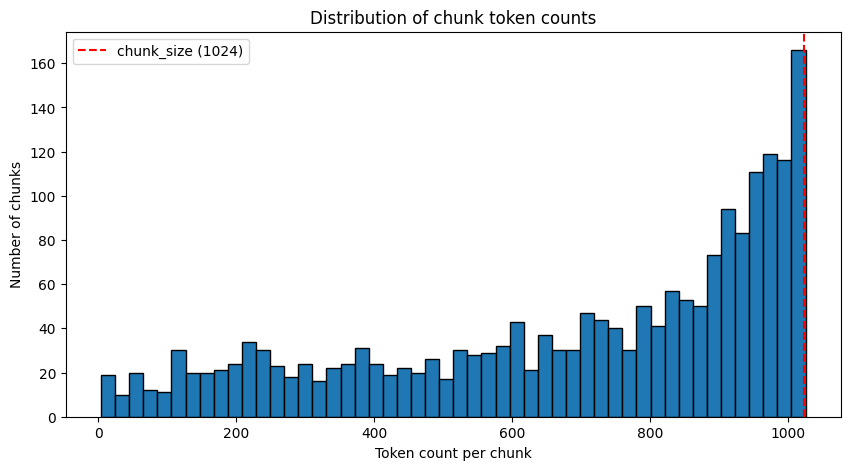


17 chunks under 20 tokens — likely fragments, worth a look:
  [huggingface/pytorch-image-models/blob/main/hfdocs/source/models/res2net.mdx] -> '```'
  [huggingface/transformers/blob/main/notebooks/README.md] -> '### PyTorch Examples'
  [huggingface/transformers/blob/main/notebooks/README.md] -> '#### Natural Language Processing[[pytorch-nlp]]'
  [huggingface/transformers/blob/main/notebooks/README.md] -> '#### Computer Vision[[pytorch-cv]]'
  [huggingface/transformers/blob/main/notebooks/README.md] -> '#### Biological Sequences[[pytorch-bio]]'
  [huggingface/transformers/blob/main/notebooks/README.md] -> '#### Natural Language Processing[[tensorflow-nlp]]'
  [huggingface/course/blob/main/README.md] -> '## 🌎 Languages and translations'
  [huggingface/transformers/blob/main/templates/adding_a_new_model/ADD_NEW_MODEL_PROPOSAL_TEMPLATE.md] -> '# retrieve matching layer weights, e.g. by'
  [gradio-app/gradio/blob/main/CHANGELOG.md] -> '### Features'
  [gradio-app/gradio/blob/main/CHANGELOG

In [ ]:
# ---  Histogram of token counts per chunk ---

# Reuse the same tokenizer used for splitting, so counts match what the splitter saw
token_counts = [len(tokenizer.encode(doc.page_content)) for doc in docs_processed]

df = pd.DataFrame({"token_count": token_counts})
print(df.describe())

plt.figure(figsize=(10, 5))
plt.hist(token_counts, bins=50, edgecolor="black")
plt.axvline(1024, color="red", linestyle="--", label="chunk_size (1024)")
plt.xlabel("Token count per chunk")
plt.ylabel("Number of chunks")
plt.title("Distribution of chunk token counts")
plt.legend()
plt.show()

# Flag any chunk that's suspiciously small (likely a fragment/orphaned heading)
tiny_chunks = [doc for doc, tc in zip(docs_processed, token_counts) if tc < 20]
print(f"\n{len(tiny_chunks)} chunks under 20 tokens — likely fragments, worth a look:")
for chunk in tiny_chunks:
    print(f"  [{chunk.metadata['source']}] -> {chunk.page_content!r}")

This distribution looks healthy overall. A few observations:

**The good**:

Mean (692) and median (788) sit comfortably below our 1024 limit, with most chunks (75th percentile = 947) using the space well — no evidence of aggressive under-splitting.
Max (1026) is right at our ceiling, which is expected and correct — the splitter isn't overshooting.
Only 17 out of 1991 chunks (0.85%) are under 20 tokens. That's a very low fragment rate — nothing to be concerned about structurally.

**Looking at the actual fragments, they fall into two categories**:

Harmless artifacts: ``` (a lone closing code fence), `@gradio/imageeditor` (a short inline-code title) — these are basically noise chunks. They carry near-zero retrieval value but also do no harm; they'll rarely if ever be the top-k match for a real query.

Orphaned headers with no body: '#### Computer Vision[[pytorch-cv]]' and '### Fixes' — these are the ones actually worth fixing, since a header with no content is retrieval-useless (it'll never usefully answer a query) and worse, if it does get retrieved, it gives the LLM a heading with no substance to work from. At this scale (0.85% fragment rate), it's very unlikely to move our retrieval metrics. Our chunking pipeline is in good shape to move on.

## 4. Embeddings

Generate vector embeddings for each chunk.

We initially used "BAAI/bge-small-en-v1.5", which is trained for English text. Based on analysis of retrieval effectiveness, we found that many of the failure cases were for contexts that were in non-English languages. There are many docs that are not in English in our document set. `BAAI/bge-small-en-v1.5` is primarily trained for embedding English text.

So, we moved to `bge-m3` model for embedding. `bge-m3` offers both multilingual and multifunctionality (dense, sparse, Colbert retrieval) support. We'll use both dense and sparse embeddings (i.e., **hybrid retrieval**) to improve retrieval effectiveness.

### Embeddings with `BAAI/bge-small-en-v1.5`

In [ ]:
'''
from sentence_transformers import SentenceTransformer

# We initially used "BAAI/bge-small-en-v1.5", which is trained for English text.
# Based on analysis of retrieval effectiveness, we found that many of the failure
# cases were for contexts that were in non-English languages.
# There are many docs that are not in English in our document set.
# `BAAI/bge-small-en-v1.5` is primarily trained for embedding English text.
# We can try with a multilingual model like `BAAI/bge-m3`.

# Load the embedding model
EMBEDDING_MODEL = "BAAI/bge-small-en-v1.5"
embedding_model = SentenceTransformer(EMBEDDING_MODEL)

print(f"Loaded embedding model: {EMBEDDING_MODEL}")

# Test embedding
test_embedding = embedding_model.encode(["This is a test"], normalize_embeddings=True)
EMBEDDING_DIM = len(test_embedding[0])
print(f"Embedding dimension: {EMBEDDING_DIM}")
'''

pass

In [ ]:
'''
def generate_embeddings(texts: List[str], model: SentenceTransformer, batch_size: int = 32) -> List[List[float]]:
    """
    Generate embeddings for a list of texts.

    Args:
        texts: List of text strings to embed
        model: SentenceTransformer model
        batch_size: Number of texts to process at once

    Returns:
        List of embedding vectors (as lists of floats)
    """
    all_embeddings = []

    # Generate embeddings in batches
    for batch_start in tqdm(range(0, len(texts), batch_size)):
      batch_end = min(batch_start + batch_size, len(texts))
      batch_texts = texts[batch_start:batch_end]

      batch_embeddings = model.encode(batch_texts, normalize_embeddings=True, show_progress_bar=False)

      all_embeddings.extend(batch_embeddings.tolist())

    return all_embeddings
    '''

pass

In [ ]:
# Generate embeddings for all chunks
'''
chunk_texts = [chunk["text"] for chunk in chunks]
embeddings = generate_embeddings(chunk_texts, embedding_model)

print(f"\nGenerated {len(embeddings)} embeddings")
if embeddings:
    print(f"Embedding dimension: {len(embeddings[0])}")
    print(f"Sample embedding (first 10 values): {embeddings[0][:10]}")
'''

pass

### Generate embeddings using `bge-m3`

In [ ]:
from FlagEmbedding import BGEM3FlagModel
from typing import List, Dict
from tqdm import tqdm

import logging
import os

# Disable standard logging messages from FlagEmbedding
logging.getLogger("FlagEmbedding").setLevel(logging.ERROR)

# Load the embedding model
EMBEDDING_MODEL = "BAAI/bge-m3"
embedding_model = BGEM3FlagModel(EMBEDDING_MODEL, use_fp16=True)  # fp16 = faster, minimal quality loss

print(f"Loaded embedding model: {EMBEDDING_MODEL}")

# Test embedding
test_output = embedding_model.encode(
    ["This is a test"], return_dense=True, return_sparse=True, return_colbert_vecs=False
)
EMBEDDING_DIM = len(test_output["dense_vecs"][0])
print(f"Dense embedding dimension: {EMBEDDING_DIM}")  # 1024 for bge-m3

Loaded embedding model: BAAI/bge-m3
Dense embedding dimension: 1024


In [ ]:
def generate_embeddings(
    texts: List[str], model: BGEM3FlagModel, batch_size: int = 24, max_length: int = 1024
) -> Dict[str, list]:
    """
    Generate hybrid (dense + sparse) embeddings for a list of texts.

    Returns:
        {
            "dense": List[List[float]]      -> one dense vector per text
            "sparse": List[Dict[int, float]] -> one sparse dict {token_id: weight} per text
        }
    """
    all_dense = []
    all_sparse = []

    for batch_start in tqdm(range(0, len(texts), batch_size)):
        batch_end = min(batch_start + batch_size, len(texts))
        batch_texts = texts[batch_start:batch_end]

        output = model.encode(
            batch_texts,
            batch_size=batch_size,
            max_length=max_length,
            return_dense=True,
            return_sparse=True,
            return_colbert_vecs=False,  # skip ColBERT vectors unless you need multi-vector search too
        )

        all_dense.extend(output["dense_vecs"].tolist())
        all_sparse.extend(output["lexical_weights"])  # list of {token_id: weight} dicts

    return {"dense": all_dense, "sparse": all_sparse}

# Run it
embeddings = generate_embeddings([doc.page_content for doc in docs_processed], embedding_model)

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 22.98it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 27.07it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 33.45it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 23.39it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 18.57it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 27.50it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 32.24it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 25.88it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 32.41it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 40.96it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 26.18it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 23.79it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 31.95it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 25.10it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 28.61it/s]

pre tokenize: 100%|██████████| 1/1 [00:00<00:00, 20.27it/s]

pre tokenize: 100%|█████

Save the embeddings in a file to avoid regenerating the embeddings in every run (consumes too much time without a GPU)

In [ ]:
import pickle

In [ ]:
# Save
with open("/content/drive/MyDrive/hf_docs_embeddings_bge_m3.pkl", "wb") as f:
    pickle.dump(embeddings, f)  # embeddings = {"dense": [...], "sparse": [...]}

pass

In [ ]:
# Load
with open("/content/drive/MyDrive/hf_docs_embeddings_bge_m3.pkl", "rb") as f:
    embeddings = pickle.load(f)

## 5. Vector Store (Milvus)

Store embeddings in Milvus for efficient similarity search.

1. Implement `setup_milvus_collection` to create a new collection
2. Implement `insert_data_to_milvus` to insert chunks and embeddings


In [ ]:
# Build dictionary of chunks to insert into the vector database
chunks = [
    {
        "id": i,
        "text": doc.page_content,
        "source": doc.metadata["source"],
    }
    for i, doc in enumerate(docs_processed)
]

In [ ]:
from pymilvus import MilvusClient

# Initialize Milvus client (uses Milvus Lite - stores data locally)
MILVUS_DB_PATH = "./hf_docs_milvus.db"
milvus_client = MilvusClient(uri=MILVUS_DB_PATH)

COLLECTION_NAME = "hf_documentation"

print(f"Milvus client initialized with database: {MILVUS_DB_PATH}")

Milvus client initialized with database: ./hf_docs_milvus.db


In [ ]:
# Suppress AllocTimestamp exception — a benign, harmless logging quirk caused
# by using Milvus Lite (the local, file-based version of Milvus) instead of
# a standalone Docker-based Milvus server.

import logging
import traceback

class GrpcAllocTimestampFilter(logging.Filter):
    def filter(self, record: logging.LogRecord) -> bool:
        if record.name != "grpc._server":
            return True
        if "Exception calling application: Method not implemented!" not in record.getMessage():
            return True
        if not record.exc_info:
            return True
        exc_text = "".join(traceback.format_exception(*record.exc_info))
        return "AllocTimestamp" not in exc_text

# Apply the filter to the gRPC server logger to silence the error noise
grpc_logger = logging.getLogger("grpc._server")
grpc_logger.addFilter(GrpcAllocTimestampFilter())


### Set up Milvus Collection

This is earlier code that supports only dense vectors.

In [ ]:
'''
def setup_milvus_collection(client: MilvusClient, collection_name: str, embedding_dim: int):
    """
    Create a Milvus collection for storing document embeddings.

    Args:
        client: MilvusClient instance
        collection_name: Name of the collection to create
        embedding_dim: Dimension of the embedding vectors
    """
    # Create a Milvus collection
    #
    # Step 1: Check if collection already exists using client.has_collection()
    # Step 2: If exists, drop it using client.drop_collection()
    # Step 3: Create new collection using client.create_collection() with:
    #   - collection_name: the name parameter
    #   - dimension: embedding_dim parameter
    #   - metric_type: "IP" (Inner Product for cosine similarity)
    #   - consistency_level: "Strong"

    if client.has_collection(collection_name=collection_name):
      client.drop_collection(collection_name=collection_name)

    client.create_collection(
        collection_name=collection_name,
        dimension=embedding_dim,
        metric_type="IP", # defaults to cosine similarity as we're using normalized embeddings
        consistency_level="Strong"
    )

    print(f"Created collection: {collection_name} with dimension {embedding_dim}")
'''

pass

Collection setup with dense + sparse fields

In [ ]:
from pymilvus import MilvusClient, DataType

def setup_milvus_collection(client: MilvusClient, collection_name: str, embedding_dim: int):
    """
    Create a Milvus collection for storing hybrid (dense + sparse) document embeddings.

    Args:
        client: MilvusClient instance
        collection_name: Name of the collection to create
        embedding_dim: Dimension of the dense embedding vectors
    """
    if client.has_collection(collection_name=collection_name):
        client.drop_collection(collection_name=collection_name)

    # Build an explicit schema — needed because we have two vector fields (dense + sparse),
    # which the simple create_collection(dimension=...) shortcut doesn't support
    schema = client.create_schema(auto_id=False, enable_dynamic_field=False)

    schema.add_field(field_name="id", datatype=DataType.INT64, is_primary=True)
    schema.add_field(field_name="text", datatype=DataType.VARCHAR, max_length=8192)
    schema.add_field(field_name="source", datatype=DataType.VARCHAR, max_length=512)
    schema.add_field(field_name="dense_vector", datatype=DataType.FLOAT_VECTOR, dim=embedding_dim)
    schema.add_field(field_name="sparse_vector", datatype=DataType.SPARSE_FLOAT_VECTOR)

    # Each vector field needs its own index — dense uses HNSW, sparse uses its own inverted index
    index_params = client.prepare_index_params()
    index_params.add_index(
        field_name="dense_vector",
        index_type="HNSW",
        metric_type="IP",  # inner product = cosine similarity, since bge-m3 dense vecs are normalized
        params={"M": 16, "efConstruction": 200},
    )
    index_params.add_index(
        field_name="sparse_vector",
        index_type="SPARSE_INVERTED_INDEX",
        metric_type="IP",
    )

    client.create_collection(
        collection_name=collection_name,
        schema=schema,
        index_params=index_params,
        consistency_level="Strong",
    )

    print(f"Created collection: {collection_name} with dense_dim={embedding_dim} + sparse vector field")

In [ ]:
# Setup the collection
setup_milvus_collection(milvus_client, COLLECTION_NAME, EMBEDDING_DIM)

Created collection: hf_documentation with dense_dim=1024 + sparse vector field


### Data Insertion

Earlier code that supports only dense embeddings.

In [ ]:
'''
def insert_data_to_milvus(
    client: MilvusClient,
    collection_name: str,
    chunks: List[Dict],
    embeddings: List[List[float]],
    batch_size: int = 100
):
    """
    Insert document chunks and embeddings into Milvus.

    Args:
        client: MilvusClient instance
        collection_name: Name of the collection
        chunks: List of chunk dictionaries with text and metadata
        embeddings: List of embedding vectors
        batch_size: Number of records to insert at once

    Returns:
        Total number of inserted records
    """
    total_inserted = 0

    # Insert data into Milvus

    # Prepare data as a list of dictionaries

    # chunk_all_documents was tweaked to hold the metadata in chunk['id']
    # instead of chunk['chunk_id']
    for i, chunk in enumerate(chunks):
      chunk['vector'] = embeddings[i]

    # Insert in batches
    for batch_start in tqdm(range(0, len(chunks), batch_size)):
      batch_end = min(batch_start + batch_size, len(chunks))
      batch = chunks[batch_start:batch_end]

      result = client.insert(collection_name=collection_name, data=batch)
      total_inserted += result["insert_count"]

    return total_inserted
'''
pass

**Insert dense + sparse embeddings**

Our embeddings dict has the shape {"dense": [...], "sparse": [...]} — so the insert function needs to pull from both instead of a single embeddings list.

In [ ]:
def insert_data_to_milvus(
    client: MilvusClient,
    collection_name: str,
    chunks: List[Dict],
    embeddings: Dict[str, list],  # {"dense": [...], "sparse": [...]}
    batch_size: int = 100
):
    """
    Insert document chunks with hybrid (dense + sparse) embeddings into Milvus.

    Args:
        client: MilvusClient instance
        collection_name: Name of the collection
        chunks: List of chunk dictionaries with text and metadata (chunk['id'] as primary key)
        embeddings: Dict with "dense" and "sparse" embedding lists, aligned by index to chunks
        batch_size: Number of records to insert at once

    Returns:
        Total number of inserted records
    """
    total_inserted = 0

    # Step 1: Attach both vector types to each chunk dict
    for i, chunk in enumerate(chunks):
        chunk["dense_vector"] = embeddings["dense"][i]
        chunk["sparse_vector"] = embeddings["sparse"][i]  # {token_id: weight} dict — pymilvus accepts this directly

    # Step 2: Insert in batches
    for batch_start in tqdm(range(0, len(chunks), batch_size)):
        batch_end = min(batch_start + batch_size, len(chunks))
        batch = chunks[batch_start:batch_end]

        result = client.insert(collection_name=collection_name, data=batch)
        total_inserted += result["insert_count"]

    return total_inserted

In [ ]:
# Insert data into Milvus
inserted_count = insert_data_to_milvus(milvus_client, COLLECTION_NAME, chunks, embeddings)

print(f"\nInserted {inserted_count} records into Milvus")

if inserted_count == len(chunks):
    print("All chunks inserted successfully!")
else:
    print("Not all chunks were inserted. Check your implementation.")

100%|██████████| 20/20 [00:02<00:00,  7.25it/s]


Inserted 1991 records into Milvus
All chunks inserted successfully!


## 6. Retrieval

Retrieve relevant documents for a query.


### Implementation of Semantic Search

This was our initial implementation before moving to `bge-m3` and hybrid search (BM25 + semantic search).

In [ ]:
# The `@track` decorator automatically instruments the function for Opik.
# It captures inputs, outputs, execution time, and any nested tracked calls.

'''
@track
def retrieve_documents(
    query: str,
    client: MilvusClient,
    collection_name: str,
    embedding_model: SentenceTransformer,
    top_k: int = 5
) -> List[Dict]:
    """
    Retrieve the most relevant documents for a query.

    Args:
        query: The search query
        client: MilvusClient instance
        collection_name: Name of the collection to search
        embedding_model: Model to generate query embedding
        top_k: Number of results to return

    Returns:
        List of dictionaries with 'text', 'source', and 'score' keys
    """

    # Implement semantic search

    retrieved_docs = []

    # Generate embedding for the query
    query_embedding = embedding_model.encode([query], normalize_embeddings=True).tolist()[0]

    # Search in Milvus using client.search()
    search_results = client.search(
        collection_name=collection_name,
        data=[query_embedding],
        limit=top_k,
        search_params={"metric_type": "IP", "params": {}},
        output_fields=["text", "source"]
    )

    # Format results as list of dicts
    for result in search_results[0]:
      retrieved_docs.append({
          "text": result["entity"]["text"],
          "source": result["entity"]["source"],
          "score": result["distance"]
      })

    return retrieved_docs
'''

pass

In [ ]:
# Test retrieval
'''
test_query = "How do I fine-tune a transformer model?"

retrieved = retrieve_documents(
    query=test_query,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    top_k=3
)

print(f"Query: {test_query}")
print(f"\nRetrieved {len(retrieved)} documents:")
for i, doc in enumerate(retrieved):
    print(f"\n--- Document {i+1} (Score: {doc.get('score', 'N/A')}) ---")
    print(f"Source: {doc.get('source', 'N/A')}")
    print(f"Text: {doc.get('text', 'N/A')[:300]}...")

if len(retrieved) == 3 and all('text' in d for d in retrieved):
    print("\n✅ Retrieval test passed!")
else:
    print("\n❌ Check your retrieval implementation")
'''

pass

### Automate evaluation of retrieval effectiveness (Initial Implementation)

Use the standard open-source framework Ragas for synthetic RAG dataset generation. It automates question generation and applies evolutionary heuristics to create diverse query styles (e.g., simple, multi-context, reasoning).

In [ ]:
'''
from pymilvus import MilvusClient
from langchain_core.documents import Document

# Query records from Milvus with integer ID compatibility
results = milvus_client.query(
    collection_name=COLLECTION_NAME,
    filter="id >= 0",  # Updated for INT64 primary key field
    output_fields=["id", "text", "source"],
    limit=MAX_DOCS
)

# Convert Milvus records into LangChain Document objects
documents = [
    Document(
        page_content=item["text"],
        metadata={
            "id": str(item["id"]),
            "source": item["source"]
        }
    )
    for item in results
]
'''

pass

In [ ]:
'''
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_openai import ChatOpenAI
from ragas.testset import TestsetGenerator

# 1. Initialize HuggingFace embeddings
hf_embeddings = HuggingFaceEmbeddings(
    model_name="BAAI/bge-small-en-v1.5",
    model_kwargs={'device': 'cuda'},
    encode_kwargs={'normalize_embeddings': True}
)

# 2. Use a model that permits variable temperature (e.g. gpt-4o or gpt-4o-mini)
llm = ChatOpenAI(
    model="gpt-4o-mini",  # gpt-5.6-luna enforces fixed temperature=1, causing Ragas extraction to fail
    temperature=0
)

# 3. Build generator directly with raw LangChain objects
generator = TestsetGenerator.from_langchain(
    generator_llm=llm,
    critic_llm=llm,
    embeddings=hf_embeddings
)

# 4. Generate evaluation samples
testset = generator.generate_with_langchain_docs(
    documents=documents,
    test_size=max(1, int(0.1 * MAX_DOCS))
)

# 5. Save output
df = testset.to_pandas()
df.to_json("milvus_retrieval_eval_dataset.json", orient="records", indent=2)
'''

pass

In [ ]:
'''
import shutil

source_path = "milvus_retrieval_eval_dataset.json"
destination_path = "/content/drive/MyDrive/milvus_retrieval_eval_dataset.json"

# Copy the file to Google Drive
shutil.copy(source_path, destination_path)

print(f"File '{source_path}' successfully saved to '{destination_path}'")
'''

pass

In [ ]:
'''
import json
import numpy as np
import pandas as pd
from pymilvus import connections, Collection
from langchain_huggingface import HuggingFaceEmbeddings

# ==========================================
# 1. CONFIGURATION
# ==========================================
VECTOR_FIELD_NAME = "vector"       # Name of vector field in Milvus
ID_FIELD_NAME = "id"               # Name of chunk ID field in Milvus
K_VALUES = [1, 3, 5, 10, 20]       # Values of k to evaluate

JSON_DATASET_PATH = "/content/drive/MyDrive/milvus_retrieval_eval_dataset.json"

# ==========================================
# 2. LOAD EMBEDDING MODEL
# ==========================================
print("Loading local embedding model...")
embedder = HuggingFaceEmbeddings(
    model_name="BAAI/bge-small-en-v1.5",
    model_kwargs={'device': 'cuda'},
    encode_kwargs={'normalize_embeddings': True}
)

# ==========================================
# 3. LOAD EVALUATION DATASET
# ==========================================
with open(JSON_DATASET_PATH, "r", encoding="utf-8") as f:
    eval_data = json.load(f)

print(f"Loaded {len(eval_data)} test cases for evaluation.\n")

# ==========================================
# 4. EVALUATION LOOP
# ==========================================
results_by_k = {k: {"precision": [], "recall": []} for k in K_VALUES}
max_k = max(K_VALUES)

search_params = {
    "metric_type": "IP",  # Match our Milvus index metric (COSINE, L2, IP)
    "params": {"nprobe": 10}
}

for idx, sample in tqdm(enumerate(eval_data)):
    # Ragas testset generator outputs 'question' or 'query'
    query = sample.get("question")

    # Target ground truth chunk ID (Ragas usually stores original doc metadata or ID)
    # Adjust target_id extraction based on our chunk mapping schema
    target_id = int(sample.get("metadata")[0].get("id"))

    if not query or target_id is None:
        continue

    # Generate query embedding
    query_vector = embedder.embed_query(query)

    # Search top-max(k) in Milvus
    search_results = milvus_client.search(
        collection_name=COLLECTION_NAME,
        data=[query_vector],
        anns_field=VECTOR_FIELD_NAME,
        search_params=search_params,
        limit=max_k,
        output_fields=[ID_FIELD_NAME]
    )

    # Extract retrieved IDs
    retrieved_ids = [hit.id for hit in search_results[0]]

    # Compute metrics for each k
    for k in K_VALUES:
        top_k_ids = retrieved_ids[:k]

        # Binary hit: target chunk is present in top-k
        hit = 1 if target_id in top_k_ids else 0

        # Recall@k = Hits / Total Relevant (Total Relevant is 1 per chunk query)
        recall = float(hit)

        # Precision@k = Hits / k
        precision = hit / k

        results_by_k[k]["recall"].append(recall)
        results_by_k[k]["precision"].append(precision)

# ==========================================
# 5. DISPLAY AGGREGATED METRICS
# ==========================================
summary_data = []
for k in K_VALUES:
    mean_precision = np.mean(results_by_k[k]["precision"])
    mean_recall = np.mean(results_by_k[k]["recall"])
    summary_data.append({
        "Metric@k": f"k={k}",
        "Precision@k": f"{mean_precision:.4f}",
        "Recall@k": f"{mean_recall:.4f}"
    })

summary_df = pd.DataFrame(summary_data)
print("\n=== RETRIEVAL EVALUATION RESULTS ===")
print(summary_df.to_string(index=False))
'''

pass

In [ ]:
'''
import json
import numpy as np
import pandas as pd
from pymilvus import connections, Collection
from langchain_huggingface import HuggingFaceEmbeddings

# ==========================================
# 1. CONFIGURATION
# ==========================================
VECTOR_FIELD_NAME = "vector"       # Name of vector field in Milvus
ID_FIELD_NAME = "id"               # Name of chunk ID field in Milvus
TEXT_FIELD_NAME = "text"           # Update with text payload field name

K_VALUES = [1, 3, 5, 10, 20]       # Values of k to evaluate

JSON_DATASET_PATH = "/content/drive/MyDrive/milvus_retrieval_eval_dataset.json"
OUTPUT_FAILURE_CSV = "/content/drive/MyDrive/retrieval_failures.csv"

# ==========================================
# 2. LOAD EMBEDDING MODEL
# ==========================================
print("Loading local embedding model...")
embedder = HuggingFaceEmbeddings(
    model_name="BAAI/bge-small-en-v1.5",
    model_kwargs={'device': 'cuda'},
    encode_kwargs={'normalize_embeddings': True}
)

# ==========================================
# 3. LOAD EVALUATION DATASET
# ==========================================
with open(JSON_DATASET_PATH, "r", encoding="utf-8") as f:
    eval_data = json.load(f)

print(f"Loaded {len(eval_data)} test cases for evaluation.\n")

# ==========================================
# 4. EVALUATION LOOP
# ==========================================
results_by_k = {k: {"precision": [], "recall": []} for k in K_VALUES}
reciprocal_ranks = []
failed_samples = []

max_k = max(K_VALUES)

search_params = {
    "metric_type": "IP",  # Ensure this matches our index metric
    "params": {"nprobe": 10}
}

for idx, sample in tqdm(enumerate(eval_data)):
    query = sample.get("question")
    raw_target_id = sample.get("metadata")[0].get("id")

    if not query or raw_target_id is None:
        continue

    # Convert target ID to integer matching Milvus INT64
    try:
        target_id = int(raw_target_id)
    except (ValueError, TypeError):
        continue

    # Embed query and search Milvus
    query_vector = embedder.embed_query(query)

    search_results = milvus_client.search(
        collection_name=COLLECTION_NAME,
        data=[query_vector],
        anns_field=VECTOR_FIELD_NAME,
        search_params=search_params,
        limit=max_k,
        output_fields=[ID_FIELD_NAME, TEXT_FIELD_NAME]
    )

    retrieved_ids = [hit.id for hit in search_results[0]]

    # Calculate Reciprocal Rank (MRR)
    if target_id in retrieved_ids:
        rank = retrieved_ids.index(target_id) + 1
        reciprocal_ranks.append(1.0 / rank)
        ranks.append(rank)
    else:
        reciprocal_ranks.append(0.0)
        ranks.append(None)

    # Calculate Precision and Recall
    top_10_ids = retrieved_ids[:10]
    recall_at_10 = 1 if target_id in top_10_ids else 0

    for k in K_VALUES:
        top_k_ids = retrieved_ids[:k]
        hit = 1 if target_id in top_k_ids else 0
        results_by_k[k]["recall"].append(float(hit))
        results_by_k[k]["precision"].append(hit / k)

    # ----------------------------------------------------
    # FAILURE TRACKING (Recall@10 == 0)
    # ----------------------------------------------------
    if recall_at_10 == 0:
        # Fetch target chunk content from Milvus if available
        target_text = "N/A"
        try:
            target_res = milvus_client.query(
                collection_name=COLLECTION_NAME,
                filter=f"{ID_FIELD_NAME} == {target_id}",
                output_fields=[TEXT_FIELD_NAME]
            )
            if target_res:
                target_text = target_res[0].get(TEXT_FIELD_NAME, "N/A")
        except Exception as e:
            target_text = f"Query error: {str(e)}"

        failed_samples.append({
            "test_case_idx": idx,
            "target_id": target_id,
            "query": query,
            "target_chunk_text": target_text,
            "top_3_retrieved_ids": str(retrieved_ids[:3]),
            "target_rank_in_top_20": retrieved_ids.index(target_id) + 1 if target_id in retrieved_ids else "Not in Top 20"
        })

# ==========================================
# 5. SUMMARY & EXPORT
# ==========================================
summary_data = []
for k in K_VALUES:
    mean_precision = np.mean(results_by_k[k]["precision"])
    mean_recall = np.mean(results_by_k[k]["recall"])
    summary_data.append({
        "Metric@k": f"k={k}",
        "Precision@k": f"{mean_precision:.4f}",
        "Recall@k": f"{mean_recall:.4f}"
    })

summary_df = pd.DataFrame(summary_data)
print("=== RETRIEVAL EVALUATION RESULTS ===")
print(summary_df.to_string(index=False))

# Export failures to CSV
failures_df = pd.DataFrame(failed_samples)
failures_df.to_csv(OUTPUT_FAILURE_CSV, index=False, encoding="utf-8")
print(f"\n[+] Logged {len(failures_df)} failures (Recall@10 = 0) to '{OUTPUT_FAILURE_CSV}'.")
'''

pass

##### **Analysis of Retrieval Performance (Initial Implementation)**:

Number of test cases: 50

Metric@k Precision@k Recall@k

     k=1      0.2400   0.2400
     k=3      0.1667   0.5000
     k=5      0.1160   0.5800
    k=10      0.0640   0.6400
    k=20      0.0350   0.7000

These results reflect a healthy, functioning baseline retrieval pipeline.

**Results Breakdown**

- Recall@10 = 0.6400 (64%): For nearly two-thirds of the synthetic test cases, our top-10 retrieval successfully fetches the exact ground-truth chunk from Milvus.

- Recall@20 = 0.7000 (70%): Expanding to $k=20$ gains an extra $6\%$ in coverage.

- MRR@20 = 0.3806: On average, when the target chunk is retrieved, it appears around rank 2 to rank 3 ($\frac{1}{0.3806} \approx 2.62$).

- Precision@k Curve: Precision mathematically drops as $k$ increases ($\frac{\text{Hits}}{k}$). Because each query in our synthetic dataset links to exactly 1 ground-truth chunk, the maximum achievable Precision@$k$ is bound by $\frac{1}{k}$: At $k=1$, max theoretical precision is $1.0$ $\rightarrow$ actual is $0.2400$ ($24\%$ top-1 accuracy). At $k=5$, max theoretical precision is $0.20$ $\rightarrow$ actual is $0.1160$ ($58\%$ of theoretical maximum).

Analyze the 18 failures (Recall@10 == 0)

In [ ]:
failures_df = pd.read_csv("/content/drive/MyDrive/retrieval_failures.csv")

failures_df

,test_case_idx,target_id,query,target_chunk_text,top_3_retrieved_ids,target_rank_in_top_20
0,11,174,What is the Top 5 Accuracy achieved in the ima...,Us\n ID: res2net50_26w_4s\n LR: 0.1\n ...,"[599, 4057, 733]",Not in Top 20
1,16,16,如何通过并行处理来加快 Gradio 服务器的演示速度？,：\n\n$code_fake_diffusion\n$demo_fake_diffusio...,"[10, 14, 18]",Not in Top 20
2,17,276,What is the purpose of the Nyströmformer in th...,Behind: Scaling Human-Centered Machine Transla...,"[4523, 3085, 3087]",16
3,18,339,What parameter should be added to the training...,", args.adam_beta2),\n weight_decay=args.ada...","[5415, 4881, 3994]",Not in Top 20
4,20,412,What is the purpose of the authentication toke...,he AI vs. AI challenge and visualize them play...,"[2905, 999, 995]",13
5,23,453,What role does image generation play in the co...,"e=""lcm"")\npipe.load_lora_weights(""TheLastBen/P...","[450, 443, 796]",Not in Top 20
6,25,379,What metrics gauge auto summaries vs. human re...,rouge\n---\n\n# Metric Card for ROUGE\n\n## Me...,"[3025, 3019, 3138]",Not in Top 20
7,26,273,How does MRA boost self-attention in transform...,transformers/model_doc/mpnet)** (from Microsof...,"[4929, 5244, 3085]",Not in Top 20
8,29,153,Which method averages strategies to reduce tra...,"ates, but a sample of those"",\n\t\t\texplain: ...","[724, 857, 3055]",12
9,31,16,如何提升 Gradio 服务器演示效率？,：\n\n$code_fake_diffusion\n$demo_fake_diffusio...,"[3503, 10, 19]",Not in Top 20


##### **Analysis of the 15 cases where the target context was not in Top 20**:

(The other cases where the target context ranks between 11 and 20 can be handled using a good reranker model.)

 174: Chunking issues: the target chunk contains only partial context (e.g., cut off mid-sentence or mid-table)

 16: Context is in Chinese

 339: Context includes Chinese characters

 453: Chunking issues: the target chunk contains only partial context (e.g., cut off mid-sentence or mid-table)

 379: Seems to be an embedding issue. Question mentions "NLP." The context includes the words "natural language processing" without mentioning the abbreviation explicitly.

 273: The context is a list of citations. This testcase seems to be invalid/unimportant.

 16: Context is in Chinese

 232: The context is a list of citations. This testcase seems to be invalid/unimportant.

 202: Context is in Russian.

 312: The context doesn't seem to have information related to the query.

 59: The context is tabular data. Only a part of the table is in the context even though that is sufficient for the query.

 339: The context includes some non-English characters.

 215: The context is in Russian.

 329: Probably an embedding issue.

 201: The context is in Russian.

##### **Findings and Next Steps**:

- There are many docs that are not in English. `BAAI/bge-small-en-v1.5` is primarily trained for embedding English text. We can try with a multilingual model like `BAAI/bge-m3`.

- We see that the context is sometimes cut off mid-sentence or mid-table due to fixed size chinking. As we know that our document set consists of Markdown documents, we can try recursive chunking that preserves section hierarchies and boundaries.

- In some cases, the query is not very clear. In one of our failure cases, the query mentioned "NLP" while the context referred to "natural language processing" without explicitly mentioning "NLP." In such cases, rewording or expanding the query using an LLM before retrieval may help.


















### Retrieval Using Hybrid Search

We found a failure case for the earlier implementation where the query used an abbreviation but the document used only the expansion without the abbreviation.

We use a small local dictionary of known abbreviations (LoRA, RAG, PEFT, etc.) for a regex-based expansion to mitigate this.

In [2]:
import re

# Curated abbreviation -> expansion mapping for the HF/ML domain
# Add to this as you discover more failure cases during testing
ABBREVIATION_MAP = {
    "lora": "low-rank adaptation",
    "lcm-lora": "latent consistency model — low-rank adaptation",
    "peft": "parameter-efficient fine-tuning",
    "rag": "retrieval-augmented generation",
    "llm": "large language model",
    "nlp": "natural language processing",
    "cv": "computer vision",
    "ner": "named entity recognition",
    "pos": "parts-of-speech tagging",
    "qa": "question answering",
    "asr": "automatic speech recognition",
    "tts": "text-to-speech",
    "ppo": "proximal policy optimization",
    "rlhf": "reinforcement learning from human feedback",
    "sft": "supervised fine-tuning",
    "lm": "language model",
    "mlm": "masked language modeling",
    "clm": "causal language modeling",
    "vqa": "visual question answering",
    "ddp": "distributed data parallel",
    "fsdp": "fully sharded data parallel",
    "int8": "8-bit integer quantization",
    "fp16": "16-bit floating point precision",
    "gpu": "graphics processing unit",
    "tpu": "tensor processing unit",
    "api": "application programming interface",
    "cli": "command-line interface",
    "onnx": "open neural network exchange",
    "gguf": "gguf quantized model format",
    "bert": "bidirectional encoder representations from transformers",
}

def expand_abbreviations(query: str, abbreviation_map: dict = ABBREVIATION_MAP) -> str:
    """
    Expand known abbreviations in a query by appending their full form,
    so the expanded query contains BOTH the original abbreviation and its expansion.
    This widens the vocabulary for embedding-based matching without losing the original term.

    Args:
        query: The original user query
        abbreviation_map: Dict of lowercase abbreviation -> full expansion

    Returns:
        Query with expansions appended, e.g. "How does LoRA work?" ->
        "How does LoRA (low-rank adaptation) work?"
    """
    # Longest keys first, so "lcm-lora" wins over "lora" at the same position
    keys = sorted(abbreviation_map, key=len, reverse=True)
    pattern = re.compile(
        r"\b(" + "|".join(re.escape(k) for k in keys) + r")\b", re.IGNORECASE
    )
    seen = set()

    def repl(m):
        key = m.group(1).lower()
        if key in seen:                 # expand each abbreviation only once
            return m.group(0)
        seen.add(key)
        return f"{m.group(0)} ({abbreviation_map[key]})"

    return pattern.sub(repl, query)

In [3]:
test_queries = [
    "How do I use LoRA for fine-tuning?",
    "What's the difference between PEFT and full fine-tuning?",
    "How do I run inference on a TPU?",
    "What is attention in transformers?",  # no abbreviations — should be unchanged
]

for q in test_queries:
    print(f"Original: {q}")
    print(f"Expanded: {expand_abbreviations(q)}\n")

Original: How do I use LoRA for fine-tuning?
Expanded: How do I use LoRA (low-rank adaptation) for fine-tuning?

Original: What's the difference between PEFT and full fine-tuning?
Expanded: What's the difference between PEFT (parameter-efficient fine-tuning) and full fine-tuning?

Original: How do I run inference on a TPU?
Expanded: How do I run inference on a TPU (tensor processing unit)?

Original: What is attention in transformers?
Expanded: What is attention in transformers?



In [ ]:
from pymilvus import AnnSearchRequest, RRFRanker

def hybrid_search(
    query: str,
    client: MilvusClient,
    collection_name: str,
    model: BGEM3FlagModel,
    top_k: int = 5,
    candidate_pool_size: int = 20,
):
    """
    Perform hybrid (dense + sparse) search against the Milvus collection.

    Args:
        query: The search query text
        client: MilvusClient instance
        collection_name: Name of the collection to search
        model: BGEM3FlagModel used to embed the query
        top_k: Number of final results to return after fusion
        candidate_pool_size: Number of candidates each sub-search retrieves before fusion
                              (should be >= top_k; wider pool = better fusion quality)

    Returns:
        List of hits, each with entity fields (text, source) and a fused score
    """
    # Embed the query the same way chunks were embedded
    q_output = model.encode(
        [query],
        return_dense=True,
        return_sparse=True,
        return_colbert_vecs=False,
    )

    # Cast to float32 explicitly — use_fp16=True on the model makes dense_vecs
    # come back as float16, which Milvus's search placeholder doesn't accept here
    dense_query_vec = np.asarray(q_output["dense_vecs"][0], dtype=np.float32)

    dense_req = AnnSearchRequest(
        data=[dense_query_vec],
        anns_field="dense_vector",
        param={"metric_type": "IP", "params": {"ef": 100}},
        limit=candidate_pool_size,
    )
    sparse_req = AnnSearchRequest(
        data=[q_output["lexical_weights"][0]],
        anns_field="sparse_vector",
        param={"metric_type": "IP"},
        limit=candidate_pool_size,
    )

    results = client.hybrid_search(
        collection_name=collection_name,
        reqs=[dense_req, sparse_req],
        ranker=RRFRanker(),  # reciprocal rank fusion — combines the two ranked lists without needing tuned weights
        limit=top_k,
        output_fields=["text", "source"],
    )

    return results[0]  # results is a list (one per query); we only passed one query

Test Retrieval

In [ ]:
query = "How do I fine-tune a transformer model?"
hits = hybrid_search(query, milvus_client, COLLECTION_NAME, embedding_model)

for hit in hits:
    print(f"score={hit['distance']:.4f} | source={hit['entity']['source']}")
    print(hit['entity']['text'][:300])
    print("---")

score=0.0320 | source=huggingface/pytorch-image-models/blob/main/hfdocs/source/models/regnety.mdx
## How do I finetune this model?

You can finetune any of the pre-trained models just by changing the classifier (the last layer).

```py
>>> model = timm.create_model('regnety_002', pretrained=True, num_classes=NUM_FINETUNE_CLASSES)
```
To finetune on your own dataset, you have to write a training 
---
score=0.0313 | source=huggingface/pytorch-image-models/blob/main/docs/models/regnety.md
## How do I finetune this model?
You can finetune any of the pre-trained models just by changing the classifier (the last layer).
```python
model = timm.create_model('regnety_002', pretrained=True, num_classes=NUM_FINETUNE_CLASSES)
```
To finetune on your own dataset, you have to write a training lo
---
score=0.0306 | source=huggingface/pytorch-image-models/blob/main/docs/models/swsl-resnext.md
## How do I finetune this model?
You can finetune any of the pre-trained models just by changing the classifier

In [ ]:
query = "How do I create an inference endpoint?"
hits = hybrid_search(query, milvus_client, COLLECTION_NAME, embedding_model)

for hit in hits:
    print(f"score={hit['distance']:.4f} | source={hit['entity']['source']}")
    print(hit['entity']['text'][:300])
    print("---")

score=0.0313 | source=huggingface/blog/blob/main/deploy-hugging-face-models-easily-with-amazon-sagemaker.md
# deploy model to SageMaker Inference
predictor = huggingface_model.deploy(
   initial_instance_count=1,
   instance_type="ml.m5.xlarge"
)

# example request, you always need to define "inputs"
data = {
"inputs": {
	"question": "What is used for inference?",
	"context": "My Name is Philipp and I liv
---
score=0.0308 | source=huggingface/hf-endpoints-documentation/blob/main/docs/source/guides/create_endpoint.mdx
Create an Endpoint

After your first login, you will be directed to the [Endpoint creation page](https://ui.endpoints.huggingface.co/new). As an example, this guide will go through the steps to deploy [distilbert-base-uncased-finetuned-sst-2-english](https://huggingface.co/distilbert-base-uncased-fi
---
score=0.0308 | source=huggingface/transformers/blob/main/docs/source/en/tasks/idefics.md
## Running inference in batch mode

All of the earlier sections illustrated IDEFICS

The retrieved contexts in the test cases are very encouraging and seem to strongly indicate that retrieval is working quite well.

#### Add reranking stage on top of the hybrid search results

Reranking will pull the best-match contexts to the **top ranks** among the retrieved contexts

In [ ]:
from FlagEmbedding import FlagReranker

# Load the reranker (same "family" as bge-m3, trained for multilingual + long-doc reranking)
RERANKER_MODEL = "BAAI/bge-reranker-v2-m3"
reranker = FlagReranker(RERANKER_MODEL, use_fp16=True)

print(f"Loaded reranker: {RERANKER_MODEL}")

Loaded reranker: BAAI/bge-reranker-v2-m3


In [ ]:
def rerank_results(query: str, hits: list, reranker: FlagReranker, top_k: int = 5):
    """
    Rerank hybrid search results using a cross-encoder reranker.

    Args:
        query: The original search query
        hits: List of hit dicts from hybrid_search() (each with 'entity' containing 'text', 'source')
        reranker: FlagReranker instance
        top_k: Number of top results to return after reranking

    Returns:
        List of hits sorted by reranker score (descending), truncated to top_k,
        each with an added 'rerank_score' field
    """
    if not hits:
        return []

    # Build [query, passage] pairs — the reranker scores each pair jointly (cross-encoder),
    # unlike dense/sparse retrieval which score query and passage independently
    pairs = [[query, hit["entity"]["text"]] for hit in hits]

    scores = reranker.compute_score(
        pairs,
        normalize=True, # normalize=True -> scores in [0, 1] via sigmoid
        max_length=1024,
    )

    # compute_score returns a float directly if len(pairs) == 1, else a list — normalize to a list
    if isinstance(scores, float):
        scores = [scores]

    for hit, score in zip(hits, scores):
        hit["rerank_score"] = score

    reranked = sorted(hits, key=lambda h: h["rerank_score"], reverse=True)

    return reranked[:top_k]

Retrieve a wider candidate pool with hybrid search, then rerank down to the final top_k

In [ ]:
@track
def hybrid_search_with_expansion(
    query: str,
    client: MilvusClient,
    collection_name: str,
    embedding_model: BGEM3FlagModel,
    reranker: FlagReranker,
    abbreviation_map: dict = ABBREVIATION_MAP,
    retrieve_k: int = 15,
    final_k: int = 5,
):
    expanded_query = expand_abbreviations(query, abbreviation_map)

    if expanded_query != query:
        print(f"Original:  {query}")
        print(f"Expanded:  {expanded_query}\n")

    hits_original = hybrid_search(
        query, client, collection_name, embedding_model,
        top_k=retrieve_k, candidate_pool_size=retrieve_k * 2,
    )

    # Only run a second search if expansion actually changed something —
    # saves a redundant search call for queries with no abbreviations
    if expanded_query != query:
        hits_expanded = hybrid_search(
            expanded_query, client, collection_name, embedding_model,
            top_k=retrieve_k, candidate_pool_size=retrieve_k * 2,
        )
        all_hits = hits_original + hits_expanded
    else:
        all_hits = hits_original

    # Deduplicate by chunk id, keeping best distance score
    merged = {}
    for hit in all_hits:
        chunk_id = hit["id"]
        if chunk_id not in merged or hit["distance"] > merged[chunk_id]["distance"]:
            merged[chunk_id] = hit

    reranked = rerank_results(query, list(merged.values()), reranker, top_k=final_k)

    return reranked

In [ ]:
# Example 1
query = "How do I create an inference endpoint?"
final_results = hybrid_search_with_expansion(query, milvus_client, COLLECTION_NAME, embedding_model, reranker)

for hit in final_results:
    print(f"rerank_score={hit['rerank_score']:.4f} | source={hit['entity']['source']}")
    print(hit['entity']['text'][:300])
    print("---")

OPIK: Started logging traces to the "RAG_HuggingFaceDocs" project at https://www.comet.com/opik/api/v1/session/redirect/projects/?trace_id=01a12182-6c23-7892-8c75-4a6ef89a5886&path=aHR0cHM6Ly93d3cuY29tZXQuY29tL29waWsvYXBpLw==.


rerank_score=0.9902 | source=huggingface/hf-endpoints-documentation/blob/main/docs/source/guides/create_endpoint.mdx
Create an Endpoint

After your first login, you will be directed to the [Endpoint creation page](https://ui.endpoints.huggingface.co/new). As an example, this guide will go through the steps to deploy [distilbert-base-uncased-finetuned-sst-2-english](https://huggingface.co/distilbert-base-uncased-fi
---
rerank_score=0.9842 | source=huggingface/blog/blob/main/inference-endpoints.md
### Deploying a Private Inference Endpoint

Repeating the steps above, I select `Private` this time.

This opens a new box asking me for the identifier of the AWS account in which the endpoint will be visible. I enter the appropriate ID and click on `Create Endpoint`. 

Not sure about your AWS accou
---
rerank_score=0.9801 | source=huggingface/blog/blob/main/inference-endpoints.md
### Deploying a Protected Inference Endpoint

I simply select `Protected` and click on `Create Endpoint`.

<kbd>
  

In [ ]:
# Example 2
query = "How do I use LoRA for fine-tuning?"
final_results = hybrid_search_with_expansion(query, milvus_client, COLLECTION_NAME, embedding_model, reranker)

for hit in final_results:
    print(f"rerank_score={hit['rerank_score']:.4f} | source={hit['entity']['source']}")
    print(hit['entity']['text'][:300])
    print("---")

Original:  How do I use LoRA for fine-tuning?
Expanded:  How do I use LoRA (low-rank adaptation) for fine-tuning?

rerank_score=0.9977 | source=huggingface/blog/blob/main/lora.md
--
title: Using LoRA for Efficient Stable Diffusion Fine-Tuning
thumbnail: /blog/assets/lora/thumbnail.png
authors:
- user: pcuenq
- user: sayakpaul
---

# Using LoRA for Efficient Stable Diffusion Fine-Tuning


[LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685) i
---
rerank_score=0.9921 | source=huggingface/blog/blob/main/lora.md
## LoRA fine-tuning

Full model fine-tuning of Stable Diffusion used to be slow and difficult, and that's part of the reason why lighter-weight methods such as Dreambooth or Textual Inversion have become so popular. With LoRA, it is much easier to fine-tune a model on a custom dataset.

Diffusers no
---
rerank_score=0.9820 | source=huggingface/peft/blob/main/examples/image_classification/README.md
Fine-tuning for image classification using LoRA and

In [ ]:
# Example 3 (the failure case in the earlier implementation)
query = "What metrics gauge auto summaries vs. human refs in NLP?"
final_results = hybrid_search_with_expansion(query, milvus_client, COLLECTION_NAME, embedding_model, reranker)

for hit in final_results:
    print(f"rerank_score={hit['rerank_score']:.4f} | source={hit['entity']['source']}")
    print(hit['entity']['text'][:300])
    print("---")

Original:  What metrics gauge auto summaries vs. human refs in NLP?
Expanded:  What metrics gauge auto summaries vs. human refs in NLP (natural language processing)?

rerank_score=0.5382 | source=huggingface/evaluate/blob/main/metrics/rouge/README.md
--
title: ROUGE
emoji: 🤗 
colorFrom: blue
colorTo: red
sdk: gradio
sdk_version: 3.19.1
app_file: app.py
pinned: false
tags:
- evaluate
- metric
description: >-
  ROUGE, or Recall-Oriented Understudy for Gisting Evaluation, is a set of metrics and a software package used for
  evaluating automatic su
---
rerank_score=0.2024 | source=huggingface/datasets/blob/main/docs/source/about_metrics.mdx
All about metrics

<Tip warning={true}>

Metrics is deprecated in 🤗 Datasets. To learn more about how to use metrics, take a look at the library 🤗 [Evaluate](https://huggingface.co/docs/evaluate/index)! In addition to metrics, you can find more tools for evaluating models and datasets.

</Tip>

🤗 Da
---
rerank_score=0.0888 | source=huggingface/course/b

We notice that abbreviation expansion helped in the NLP-related query, as most docs used the expansion (natural language processing) directly.

### Retrieval Evaluation (Precision@k and Recall@k)

**Generate evaluation dataset**

We move to a custom generator as we faced too many (unresolvable) incompatibilities between the *latest* Ragas Testsetgenerator and langchain modules in the previous attempt.

In [ ]:
import json
import random
from openai import OpenAI
from tqdm import tqdm

SEED = 39

client = OpenAI()  # picks up OPENAI_API_KEY from environment

QUESTION_GEN_PROMPT = """You are creating an evaluation dataset for a Hugging Face documentation Q&A / RAG system.

Given the following documentation excerpt, write ONE realistic question a developer might ask that can be answered using ONLY this excerpt, plus a concise reference answer based strictly on the excerpt.

Rules:
- The question must be answerable from this excerpt alone, without needing other context.
- Do not reference "the excerpt" or "the document" in the question — phrase it as a natural standalone question.
- The answer must be grounded strictly in the excerpt content — do not add outside knowledge.
- If the excerpt is too short, generic, or low-content to form a meaningful question (e.g., just a header, a code fence, a changelog entry), respond with {{"skip": true}} instead.

Respond ONLY with valid JSON in this exact format, nothing else:
{{"question": "...", "answer": "..."}}
or
{{"skip": true}}

Excerpt:
---
{chunk_text}
---"""

def generate_question_for_chunk(chunk_text: str, model: str = "gpt-4o-mini") -> dict | None:
    """
    Generate a (question, answer) pair from a single chunk, or None if the chunk
    was judged unsuitable (too short/generic) for a meaningful question.
    """
    response = client.chat.completions.create(
        model=model,
        messages=[{"role": "user", "content": QUESTION_GEN_PROMPT.format(chunk_text=chunk_text)}],
        temperature=0.3,
        response_format={"type": "json_object"},  # forces valid JSON output
    )

    try:
        parsed = json.loads(response.choices[0].message.content)
    except json.JSONDecodeError:
        return None  # malformed output — skip rather than crash the whole run

    if parsed.get("skip"):
        return None

    if "question" not in parsed or "answer" not in parsed:
        return None

    return parsed


def build_eval_dataset(
    docs_processed: list,
    sample_size: int,
    model: str = "gpt-4o-mini",
    min_chunk_tokens: int = 50,
    seed: int = SEED,
) -> list[dict]:
    """
    Build an evaluation dataset by sampling chunks and generating one question
    per chunk. Ground truth chunk id is known exactly (the sampled chunk itself),
    since the question is generated directly from it.
    """
    random.seed(seed)

    # Filter out very short chunks up front (headers, code fences, etc.) —
    # cheap pre-filter before spending an LLM call on them
    eligible_indices = [
        i for i, doc in enumerate(docs_processed)
        if len(doc.page_content.split()) >= min_chunk_tokens
    ]

    sample_indices = random.sample(eligible_indices, min(sample_size, len(eligible_indices)))

    eval_records = []
    skipped = 0

    for idx in tqdm(sample_indices):
        chunk = docs_processed[idx]
        result = generate_question_for_chunk(chunk.page_content, model=model)

        if result is None:
            skipped += 1
            continue

        eval_records.append({
            "question": result["question"],
            "ground_truth_answer": result["answer"],
            "source": chunk.metadata.get("source"),
            "relevant_chunk_ids": [idx],  # exact — no fuzzy matching needed
        })

    print(f"Generated {len(eval_records)} questions, skipped {skipped} unsuitable chunks")
    return eval_records


# Run it — sample_size ~10% of our chunks
eval_records = build_eval_dataset(
    docs_processed=docs_processed,
    sample_size=max(1, int(0.1 * len(docs_processed))),
)

eval_df = pd.DataFrame(eval_records)

# Save it to a file to avoid regenerating the dataset
eval_df.to_json("/content/drive/MyDrive/milvus_hybrid_eval_dataset.json", orient="records", indent=2)

Compute Precision@k and Recall@k

In [ ]:
# Load the generated eval dataset
with open("/content/drive/MyDrive/milvus_hybrid_eval_dataset.json", "r") as f:
    eval_records = json.load(f)

eval_df = pd.DataFrame(eval_records)
print(f"Loaded {len(eval_df)} evaluation questions")

Loaded 195 evaluation questions


In [ ]:
def precision_at_k(retrieved_ids: list, relevant_ids: list, k: int) -> float:
    """
    Fraction of the top-k retrieved chunks that are actually relevant.
    """
    top_k = retrieved_ids[:k]
    if not top_k:
        return 0.0
    num_relevant_retrieved = len(set(top_k) & set(relevant_ids))
    return num_relevant_retrieved / len(top_k)


def recall_at_k(retrieved_ids: list, relevant_ids: list, k: int) -> float:
    """
    Fraction of all relevant chunks that were found within the top-k retrieved.
    """
    if not relevant_ids:
        return 0.0  # undefined case — shouldn't happen if eval set is built correctly
    top_k = retrieved_ids[:k]
    num_relevant_retrieved = len(set(top_k) & set(relevant_ids))
    return num_relevant_retrieved / len(relevant_ids)

def rr_at_k(retrieved_ids: list, relevant_ids: list, k: int) -> float:
    """Reciprocal rank of the first relevant chunk within the top-k (0 if none)."""
    for rank, chunk_id in enumerate(retrieved_ids[:k], start=1):
        if chunk_id in relevant_ids:
            return 1.0 / rank
    return 0.0

pass

In [ ]:
def evaluate_retrieval(
    eval_df: pd.DataFrame,
    client: MilvusClient,
    collection_name: str,
    embedding_model: BGEM3FlagModel,
    reranker: FlagReranker = None,  # pass None to evaluate hybrid search WITHOUT reranking
    k_values: list = [1, 3, 5, 10],
    retrieve_k: int = 20,
) -> pd.DataFrame:
    """
    Run retrieval for every question in eval_df, compute Precision@k/Recall@k
    at each k in k_values, and return a per-question + summary breakdown.
    """
    per_question_results = []

    for _, row in tqdm(eval_df.iterrows(), total=len(eval_df)):
        query = row["question"]
        relevant_ids = row["relevant_chunk_ids"]

        # Retrieve a pool wide enough to cover the largest k you're evaluating
        max_k = max(k_values)
        pool_size = max(retrieve_k, max_k)

        hits = hybrid_search_with_expansion(
            query, client, collection_name, embedding_model, reranker,
            retrieve_k=pool_size * 2, final_k=pool_size
        )

        retrieved_ids = [hit["id"] for hit in hits]

        result_row = {"question": query, "relevant_chunk_ids": relevant_ids, "retrieved_chunk_ids": retrieved_ids}
        for k in k_values:
            result_row[f"precision@{k}"] = precision_at_k(retrieved_ids, relevant_ids, k)
            result_row[f"recall@{k}"] = recall_at_k(retrieved_ids, relevant_ids, k)
            result_row[f"rr@{k}"] = rr_at_k(retrieved_ids, relevant_ids, k)

        per_question_results.append(result_row)

    return pd.DataFrame(per_question_results)


def summarize_metrics(results_df: pd.DataFrame, k_values: list) -> pd.DataFrame:
    """
    Average Precision@k/Recall@k across all questions.
    """
    summary = {}
    for k in k_values:
        summary[f"Precision@{k}"] = results_df[f"precision@{k}"].mean()
        summary[f"Recall@{k}"] = results_df[f"recall@{k}"].mean()
        summary[f"MRR@{k}"] = results_df[f"rr@{k}"].mean()

    return pd.DataFrame([summary]).T.rename(columns={0: "score"})

pass

In [ ]:
K_VALUES = [1, 3, 5, 10]

# Hybrid search + reranking
results_reranked = evaluate_retrieval(
    eval_df, milvus_client, COLLECTION_NAME, embedding_model,
    reranker=reranker, k_values=K_VALUES,
)

  3%|▎         | 5/195 [00:58<36:37, 11.56s/it]

Original:  What command should I use to finetune the t5-3b model on a single GPU with DeepSpeed?
Expanded:  What command should I use to finetune the t5-3b model on a single GPU (graphics processing unit) with DeepSpeed?



 21%|██        | 40/195 [05:34<18:15,  7.07s/it]

Original:  What is DROP in the context of the Open LLM Leaderboard?
Expanded:  What is DROP in the context of the Open LLM (large language model) Leaderboard?



 29%|██▊       | 56/195 [07:33<16:33,  7.15s/it]

...

 88%|████████▊ | 172/195 [22:30<02:43,  7.12s/it]

Original:  What can you do to improve the model after training it with RLHF?
Expanded:  What can you do to improve the model after training it with RLHF (reinforcement learning from human feedback)?



 97%|█████████▋| 189/195 [24:37<00:43,  7.24s/it]

Original:  What is the memory capacity of each ROCm device in an AMD Instinct MI250 GPU?
Expanded:  What is the memory capacity of each ROCm device in an AMD Instinct MI250 GPU (graphics processing unit)?



100%|██████████| 195/195 [25:24<00:00,  7.82s/it]


In [ ]:
summary_reranked = summarize_metrics(results_reranked, K_VALUES)
print("\nHybrid search + reranking:")
print(summary_reranked)


Hybrid search + reranking:
                 score
Precision@1   0.825641
Recall@1      0.825641
MRR@1         0.825641
Precision@3   0.309402
Recall@3      0.928205
MRR@3         0.872650
Precision@5   0.192821
Recall@5      0.964103
MRR@5         0.881368
Precision@10  0.097949
Recall@10     0.979487
MRR@10        0.883525


#### **MRR (Mean Reciprocal Rank)**

**MRR@10 = 0.8835**: the right chunk is ranked first for about 83% of questions, is in the top 3 (the context the LLM actually sees) for about 93%, and is missing from the top 10 for about 2% (4 of 195, all of them chunks that are just lists of paper citations in Korean or Russian docs). MRR@10 is the average of 1/rank of the first correct chunk within the top 10 (0 if absent). It sits barely above Recall@1, so almost all of the quality is in the top-1 hit. The remaining correct chunks mostly sit at ranks 2 and 3.

Numbers vary by about 1 to 2 points between identical runs (near-tied fp16 reranker scores and RRF ties). The figures above are from one run, and differences of that size are well inside the sampling error of a 195-question set.

#### **Recall and Precision**

Since the relevant_chunk_ids from the custom generator is always a single-item list (one chunk per question), Recall@k here effectively becomes a binary "was the source chunk found in the top-k" signal, and Precision@k will always be either 0 or 1/k — this is expected and fine given how the eval set was built. This is the reason why Precision@k seemingly "deteriorates" with increasing k while Recall@k improves with increasing k.

The numbers indicate very strong retrieval effectiveness — the expected chunk ranked #1 in ~82% of the test cases. Recall@10 is close to 100%.

It seems the combination of recursive chunking (which ensured cleanly partitioned and self-contained chunks based on section boundaries), larger `bge-m3` model with multilingual support, simple query enhancement (by expanding abbreviations), hybrid search (BM25 + semantic search), and reranking has worked out nicely.

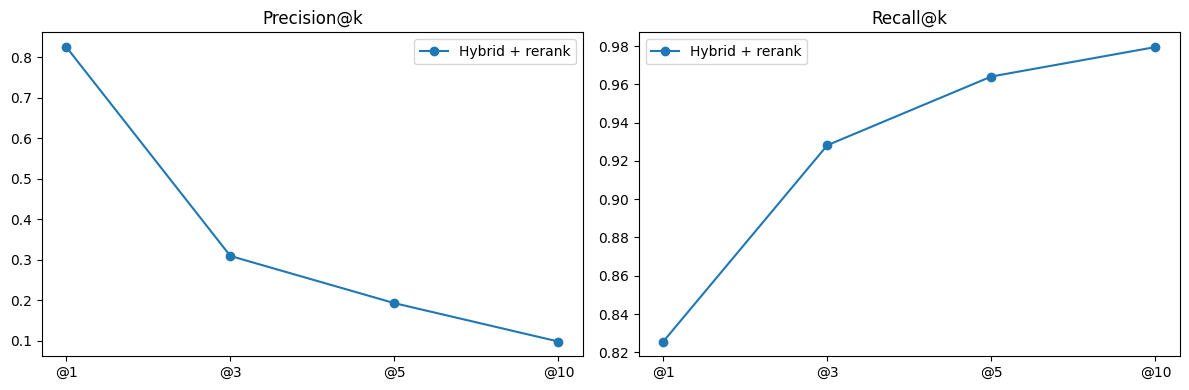

In [ ]:
import matplotlib.pyplot as plt

x = [f"@{k}" for k in K_VALUES]
precision_reranked = [summary_reranked.loc[f"Precision@{k}", "score"] for k in K_VALUES]
recall_reranked = [summary_reranked.loc[f"Recall@{k}", "score"] for k in K_VALUES]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, precision_reranked, marker='o', label='Hybrid + rerank')
axes[0].set_title("Precision@k")
axes[0].legend()

axes[1].plot(x, recall_reranked, marker='o', label='Hybrid + rerank')
axes[1].set_title("Recall@k")
axes[1].legend()

plt.tight_layout()
plt.show()

Inspect the cases where even Recall@10 failed

In [ ]:
failures = results_reranked[results_reranked["recall@10"] == 0]

In [ ]:
failures = results_reranked[results_reranked["recall@10"] == 0]
print(f"{len(failures)} / {len(results_reranked)} questions had zero recall at k=10")

def inspect_retrieval_failures(
    failures: pd.DataFrame,
    client: MilvusClient,
    collection_name: str,
    preview_chars: int = 600,
):
    """
    For each zero-recall@10 failure, print the question alongside the full text
    of the expected (relevant) chunk, fetched directly from Milvus.
    """
    for _, row in failures.iterrows():
        expected_ids = row["relevant_chunk_ids"]

        fetched = client.get(
            collection_name=collection_name,
            ids=expected_ids,
            output_fields=["text", "source"],
        )

        print(f"Q: {row['question']}")
        print(f"Expected chunk id(s): {expected_ids}")

        if not fetched:
            print("  ⚠️ Could not fetch expected chunk — id may not exist in the collection")
        else:
            for chunk in fetched:
                print(f"  Source: {chunk['source']}")
                print(f"  Text:\n{chunk['text']}")
                # if len(chunk['text']) > preview_chars:
                #    print("  ...(truncated)")

        print(f"Retrieved instead (top 5): {row['retrieved_chunk_ids'][:5]}")
        print("=" * 80)

inspect_retrieval_failures(failures, milvus_client, COLLECTION_NAME)

4 / 195 questions had zero recall at k=10
Q: Who are the authors of the mLUKE paper?
Expected chunk id(s): [1516]
  Source: huggingface/transformers/blob/main/README_ko.md
  Text:
1. **[MGP-STR](https://huggingface.co/docs/transformers/model_doc/mgp-str)** (Alibaba Research 에서 제공)은 Peng Wang, Cheng Da, and Cong Yao.의 [Multi-Granularity Prediction for Scene Text Recognition](https://arxiv.org/abs/2209.03592)논문과 함께 발표했습니다.
1. **[Mistral](https://huggingface.co/docs/transformers/model_doc/mistral)** (from Mistral AI) by The Mistral AI team: Albert Jiang, Alexandre Sablayrolles, Arthur Mensch, Chris Bamford, Devendra Singh Chaplot, Diego de las Casas, Florian Bressand, Gianna Lengyel, Guillaume Lample, Lélio Renard Lavaud, Lucile Saulnier, Marie-Anne Lachaux, Pierre Stock, Teven Le Scao, Thibaut Lavril, Thomas Wang, Timothée Lacroix, William El Sayed.. 
1. **[Mixtral](https://huggingface.co/docs/transformers/model_doc/mixtral)** (from Mistral AI) by The [Mistral AI](https://mistral.ai) tea

All four target chunks are lists of paper citations, two in Korean and two in Russian. The answer has to be inferred from a single paper title inside the list, so these chunks carry almost no retrieval signal. These are genuinely hard cases, and none of the four involves ordinary prose or code documentation.

## 7. Generation

Generate answers using the retrieved context chunks.

### Initial Implementation using `Phi-3.5-mini-instruct` model (open model from Hugging Face)

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, pipeline
import torch

# Quantize Phi-3.5-mini-instruct to allow greater legroom after the
# introduction of bge-m3 and bge-reranker-v2-m3.
# 4-bit quantization via bitsandbytes — shrinks Phi-3.5-mini from ~7.6GB to ~2.2GB,
# with typically small quality impact for a model this size.
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

# Load the language model for generation
GENERATION_MODEL = "microsoft/Phi-3.5-mini-instruct"

print(f"Loading model: {GENERATION_MODEL}")
print("This may take a few minutes...")

tokenizer = AutoTokenizer.from_pretrained(GENERATION_MODEL)
gen_model = AutoModelForCausalLM.from_pretrained(
    GENERATION_MODEL,
    quantization_config=bnb_config,
    device_map="auto", #"cuda" or "auto"
)

# Create text generation pipeline
generator = pipeline(
    "text-generation",
    model=gen_model,
    tokenizer=tokenizer
)

print(f"Model loaded successfully!")

pass

Loading model: microsoft/Phi-3.5-mini-instruct
This may take a few minutes...


[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


Model loaded successfully!


In [ ]:
# Initialize Opik LLM-based answer quality metrics
answer_relevance_metric = AnswerRelevance(model="gpt-4o-mini")
hallucination_metric = Hallucination(model="gpt-4o-mini")

Define the system prompt for RAG usecase

In [ ]:
# Prompt template for RAG
SYSTEM_PROMPT = (
    "You are a precise, factual assistant that answers questions using ONLY "
    "the provided context. Follow these rules strictly:\n"
    "1. Base your answer entirely on the CONTEXT below — do not use outside knowledge.\n"
    "2. If the answer is not contained in the context, say exactly: "
    "\"I don't have enough information to answer that.\"\n"
    "3. Cite the source number(s) you used, like [1] or [2, 3], in your "
    "answer text. Cite/list all and only the source(s) you based your answer on.\n"
    "4. Be precise. Strictly avoid irrelevant text in your answers."
)

The code in the following two cells correspond to our initial retrieval implementation without hybrid search

In [ ]:
'''
from transformers import GenerationConfig

# The `@track` decorator automatically instruments the function for Opik.
# It captures inputs, outputs, execution time, and any nested tracked calls.
@track
def generate_answer(
    query: str,
    retrieved_docs: List[Dict],
    generator: pipeline,
    max_new_tokens: int = 256
) -> Dict:
    """
    Generate an answer using retrieved documents as context.

    Args:
        query: The user's question
        retrieved_docs: List of retrieved document dictionaries
        generator: HuggingFace text generation pipeline
        max_new_tokens: Maximum tokens to generate

    Returns:
        Dictionary with 'answer', 'context', 'query', and 'retrieved_docs'
    """
    # Generate an answer using the RAG pattern

    retrieved_chunks = []

    for doc in retrieved_docs:
      retrieved_chunks.append(doc["text"])

    # Combine retrieved documents into context
    context = "\n\n".join(
        f"[{i+1}] Source Name: {doc["source"]} {doc["text"]}" for i, doc in enumerate(retrieved_docs)
    )

    # Format the prompt
    user_msg = f"CONTEXT:\n{context}\n\nQUESTION:\n{query}"
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_msg},
    ]

    rag_prompt = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

    # Define our parameters explicitly in a GenerationConfig
    gen_config = GenerationConfig(
      max_new_tokens=max_new_tokens,
      max_length=None, # avoids conflict/warning with max_new_tokens
      do_sample=True,
      temperature=0.7,
      top_p=0.9,
      eos_token_id=tokenizer.eos_token_id,
      pad_token_id=tokenizer.pad_token_id
    )

    outputs = generator(
      rag_prompt,
      generation_config=gen_config,
      return_full_text=False
    )

    answer = outputs[0]["generated_text"].strip()

    return {
        "query": query,
        "answer": answer,
        "context": context,
        "retrieved_docs": retrieved_docs
    }
'''

pass

In [ ]:
'''
# Test generation
test_query = "How do I fine-tune a transformer model?"

# Retrieve relevant documents
retrieved = retrieve_documents(
    query=test_query,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    top_k=3
)

# Generate answer
result = generate_answer(
    query=test_query,
    retrieved_docs=retrieved,
    generator=generator
)

print(f"Question: {result['query']}")
print(f"\nAnswer: {result['answer']}")

if result['answer'] and len(result['answer']) > 10:
    print("\nGeneration test passed!")
else:
    print("\nCheck your generation implementation")
'''

pass

`generate_answer()` updated for hybrid_search_with_expansion

In [ ]:
from transformers import GenerationConfig

@track
def generate_answer(
    query: str,
    retrieved_hits: List[Dict],  # renamed from retrieved_docs — these are hybrid_search_with_expansion() hits
    generator: pipeline,
    tokenizer,
    max_new_tokens: int = 256
) -> Dict:
    """
    Generate an answer using retrieved hits (from hybrid_search_with_expansion) as context.

    Args:
        query: The user's question
        retrieved_hits: List of hit dicts from hybrid_search_with_expansion(),
                         each shaped {"id":, "distance":, "entity": {"text":, "source":}, "rerank_score":}
        generator: HuggingFace text generation pipeline
        tokenizer: tokenizer used to build the chat-formatted prompt
        max_new_tokens: Maximum tokens to generate

    Returns:
        Dictionary with 'answer', 'context', 'query', and 'retrieved_hits'
    """
    # Build numbered context from each hit's entity.text / entity.source
    context = "\n\n".join(
        f"[{i+1}] Source Name: {hit['entity']['source']}\n{hit['entity']['text']}"
        for i, hit in enumerate(retrieved_hits)
    )

    user_msg = f"CONTEXT:\n{context}\n\nQUESTION:\n{query}"
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_msg},
    ]

    rag_prompt = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

    gen_config = GenerationConfig(
        max_new_tokens=max_new_tokens,
        max_length=None,
        do_sample=True,
        temperature=0.7,
        top_p=0.9,
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.pad_token_id,
    )

    outputs = generator(
        rag_prompt,
        generation_config=gen_config,
        return_full_text=False,
    )

    answer = outputs[0]["generated_text"].strip()

    return {
        "query": query,
        "answer": answer,
        "context": context,
        "retrieved_hits": retrieved_hits,
    }

Test generation — using `hybrid_search_with_expansion()`

In [ ]:
import re

# Code to extract the cited sources from an answer
def extract_cited_sources(answer: str, retrieved_hits: List[Dict]) -> Dict:
    """
    Parse citation markers like [1], [2, 3], [1,2,3] from the generated answer,
    and map them back to the actual source names from retrieved_hits.

    Args:
        answer: The LLM-generated answer text containing citation markers
        retrieved_hits: The same list of hits passed into generate_answer(),
                         used to map citation numbers back to source names
                         (citation number N corresponds to retrieved_hits[N-1])

    Returns:
        {
            "cited_numbers": sorted list of unique citation numbers found, e.g. [1, 3]
            "cited_sources": list of corresponding source names
            "uncited_sources": sources that were retrieved but NOT cited
            "invalid_citations": citation numbers that don't correspond to any retrieved hit
                                  (e.g. the model hallucinated a [5] when only 3 sources existed)
        }
    """
    # Matches [1], [2, 3], [2,3,4], with optional spaces after commas
    citation_pattern = r"\[(\d+(?:\s*,\s*\d+)*)\]"
    matches = re.findall(citation_pattern, answer)

    cited_numbers = set()
    for match in matches:
        numbers = [int(n.strip()) for n in match.split(",")]
        cited_numbers.update(numbers)

    cited_numbers = sorted(cited_numbers)

    cited_sources = []
    invalid_citations = []
    for num in cited_numbers:
        idx = num - 1  # citation [1] corresponds to retrieved_hits[0]
        if 0 <= idx < len(retrieved_hits):
            cited_sources.append(retrieved_hits[idx]["entity"]["source"])
        else:
            invalid_citations.append(num)

    all_sources = [hit["entity"]["source"] for hit in retrieved_hits]
    uncited_sources = [src for src in all_sources if src not in cited_sources]

    return {
        "cited_numbers": cited_numbers,
        "cited_sources": cited_sources,
        "uncited_sources": uncited_sources,
        "invalid_citations": invalid_citations,
    }

In [ ]:
test_query = "How do I fine-tune a transformer model?"

# Retrieve using hybrid search + query expansion + reranking (all built into this one call)
retrieved = hybrid_search_with_expansion(
    query=test_query,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    reranker=reranker,
    retrieve_k=15,
    final_k=3,
)

# Generate answer
result = generate_answer(
    query=test_query,
    retrieved_hits=retrieved,
    generator=generator,
    tokenizer=tokenizer,
)

citation_info = extract_cited_sources(result["answer"], result["retrieved_hits"])

print(f"Question: {result['query']}")

print(f"\nAnswer: {result['answer']}")

print("Cited sources:")
for num, src in zip(citation_info["cited_numbers"], citation_info["cited_sources"]):
    print(f"  [{num}] {src}")

if citation_info["uncited_sources"]:
    print(f"\nRetrieved but not cited ({len(citation_info['uncited_sources'])}):")
    for src in citation_info["uncited_sources"]:
        print(f"  - {src}")

if citation_info["invalid_citations"]:
    print(f"\n⚠️ Model cited source number(s) that don't exist: {citation_info['invalid_citations']}")

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Question: How do I fine-tune a transformer model?

Answer: To fine-tune a transformer model, you can follow these steps based on the provided context [1, 2, 3]:

1. Install necessary pip packages, including `git-lfs`, `datasets`, `transformers`, and `sentencepiece`.
2. Log in to your Hugging Face account to ensure models are uploaded correctly.
3. Use the `pipeline` from 🤗 Transformers to download your fine-tuned model using the `fill-mask` pipeline as an example.
4. Prepare your dataset by preprocessing it, which is essential for training the model.
5. Start training the model using the provided notebook, which can be run online with a Google Colab pro with the GPU runtime environment enabled.

Here is the code snippet from the context to illustrate the fine-tuning process using a pipeline:

```python
from transformers import pipeline

mask_filler = pipeline("fill-mask", model="huggingface-course/distilbert-base-uncased-finetuned-imdb")

preds = mask_filler(text)

for
Cited sources:
 

Complete RAG pipeline function — Updated

In [ ]:
def score_generation_quality(
    question: str,
    generated_answer: str,
    context_texts: List[str],
) -> Dict:
    """
    Score a single generated answer using Opik's Hallucination and AnswerRelevance metrics.

    Args:
        question: The original user question
        generated_answer: The LLM-generated answer
        context_texts: List of the retrieved chunk texts used as context

    Returns:
        Dict with hallucination_score, hallucination_reason, relevance_score, relevance_reason
    """
    hallucination_result = hallucination_metric.score(
        input=question,
        output=generated_answer,
        context=context_texts,
    )

    relevance_result = answer_relevance_metric.score(
        input=question,
        output=generated_answer,
        context=context_texts,
    )

    return {
        "hallucination_score": hallucination_result.value,
        "hallucination_reason": hallucination_result.reason,
        "relevance_score": relevance_result.value,           # continuous score for how relevant/appropriate the answer is
        "relevance_reason": relevance_result.reason,
    }

Full batch generation loop over `eval_df` questions

In [ ]:
import json
import time
from tqdm import tqdm

def run_generation_eval(
    eval_df: pd.DataFrame,
    client: MilvusClient,
    collection_name: str,
    embedding_model: BGEM3FlagModel,
    reranker: FlagReranker,
    generator: pipeline,
    tokenizer,
    hallucination_metric,
    answer_relevance_metric,
    retrieve_k: int = 15,
    final_k: int = 3,
    max_new_tokens: int = 256,
    save_path: str = "/content/drive/MyDrive/generation_eval_results.json",
    save_every: int = 10,
) -> pd.DataFrame:
    """
    Run the full retrieval + generation pipeline over every question in eval_df,
    and collect answers, citations, and retrieval info for later analysis.

    Args:
        eval_df: DataFrame with 'question', 'ground_truth_answer', 'relevant_chunk_ids'
        save_every: Write partial results to disk every N questions, so a crash
                    or Colab disconnect partway through doesn't lose everything
    """
    results = []

    for i, row in enumerate(tqdm(eval_df.itertuples(), total=len(eval_df))):
        query = row.question

        try:
            retrieved_hits = hybrid_search_with_expansion(
                query=query,
                client=client,
                collection_name=collection_name,
                embedding_model=embedding_model,
                reranker=reranker,
                retrieve_k=retrieve_k,
                final_k=final_k,
            )

            gen_result = generate_answer(
                query=query,
                retrieved_hits=retrieved_hits,
                generator=generator,
                tokenizer=tokenizer,
            )

            citation_info = extract_cited_sources(gen_result["answer"], retrieved_hits)

            # Score with Opik
            context_texts = [hit["entity"]["text"] for hit in retrieved_hits]
            quality_scores = score_generation_quality(
                question=query,
                generated_answer=gen_result["answer"],
                context_texts=context_texts,
            )

            retrieved_ids = [hit["id"] for hit in retrieved_hits]
            relevant_ids = row.relevant_chunk_ids
            correct_chunk_retrieved = bool(set(retrieved_ids) & set(relevant_ids))

            results.append({
                "question": query,
                "ground_truth_answer": row.ground_truth_answer,
                "relevant_chunk_ids": relevant_ids,
                "retrieved_chunk_ids": retrieved_ids,
                "correct_chunk_retrieved": correct_chunk_retrieved,
                "generated_answer": gen_result["answer"],
                "cited_numbers": citation_info["cited_numbers"],
                "cited_sources": citation_info["cited_sources"],
                "uncited_sources": citation_info["uncited_sources"],
                "invalid_citations": citation_info["invalid_citations"],
                **quality_scores,
                "error": None,
            })

        except Exception as e:
            # Don't let one bad question kill the whole run — log it and move on
            results.append({
                "question": query,
                "ground_truth_answer": row.ground_truth_answer,
                "relevant_chunk_ids": row.relevant_chunk_ids,
                "retrieved_chunk_ids": None,
                "correct_chunk_retrieved": None,
                "generated_answer": None,
                "cited_numbers": None,
                "cited_sources": None,
                "uncited_sources": None,
                "invalid_citations": None,
                "hallucination_score": None, "hallucination_reason": None,
                "relevance_score": None, "relevance_reason": None,
                "error": str(e),
            })

        # Periodic checkpoint save — protects against Colab timeouts/disconnects mid-run
        if (i + 1) % save_every == 0:
            with open(save_path, "w") as f:
                json.dump(results, f, indent=2)

    # Final save
    with open(save_path, "w") as f:
        json.dump(results, f, indent=2)

    results_df = pd.DataFrame(results)

    n_errors = results_df["error"].notna().sum()
    print(f"\nCompleted {len(results_df)} questions, {n_errors} errors")
    if n_errors > 0:
        print("Questions with errors:")
        print(results_df[results_df["error"].notna()][["question", "error"]])

    return results_df

Run the full evaluation loop

In [ ]:
generation_results = run_generation_eval(
    eval_df=eval_df,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    reranker=reranker,
    generator=generator,
    tokenizer=tokenizer,
    hallucination_metric=hallucination_metric,
    answer_relevance_metric=answer_relevance_metric,
)

  0%|          | 0/195 [00:00<?, ?it/s]OPIK: Started logging traces to the "RAG_HuggingFaceDocs_Milvus" project at https://www.comet.com/opik/api/v1/session/redirect/projects/?trace_id=01a12b51-522a-79ae-b2d9-08c2f384cf30&path=aHR0cHM6Ly93d3cuY29tZXQuY29tL29waWsvYXBpLw==.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
  3%|▎         | 5/195 [02:38<1:28:42, 28.01s/it]

Original:  What command should I use to finetune the t5-3b model on a single GPU with DeepSpeed?
Expanded:  What command should I use to finetune the t5-3b model on a single GPU (graphics processing unit) with DeepSpeed?



 21%|██        | 40/195 [16:01<59:18, 22.96s/it]

Original:  What is DROP in the context of the Open LLM Leaderboard?
Expanded:  What is DROP in the context of the Open LLM (large language model) Leaderboard?



 29%|██▊       | 56/195 [21:48<44:31, 19.22s/it]

...

Original:  What can you do to improve the model after training it with RLHF?
Expanded:  What can you do to improve the model after training it with RLHF (reinforcement learning from human feedback)?



 97%|█████████▋| 189/195 [1:19:05<02:33, 25.55s/it]

Original:  What is the memory capacity of each ROCm device in an AMD Instinct MI250 GPU?
Expanded:  What is the memory capacity of each ROCm device in an AMD Instinct MI250 GPU (graphics processing unit)?



100%|██████████| 195/195 [1:21:38<00:00, 25.12s/it]


Completed 195 questions, 0 errors


Quick summary stats

In [ ]:
valid_results = generation_results[generation_results["error"].isna()]

print(f"Chunk retrieval success rate: {valid_results['correct_chunk_retrieved'].mean():.2%}")
print(f"Avg citations per answer: {valid_results['cited_numbers'].apply(len).mean():.2f}")
print(f"Answers with invalid citations: {(valid_results['invalid_citations'].apply(len) > 0).sum()} / {len(valid_results)}")
print(f"Answers with zero citations: {(valid_results['cited_numbers'].apply(len) == 0).sum()} / {len(valid_results)}")

print(f"Hallucination rate: {valid_results['hallucination_score'].mean():.2%}")
print(f"Avg answer relevance: {valid_results['relevance_score'].mean():.3f}")

Chunk retrieval success rate: 93.33%
Avg citations per answer: 0.66
Answers with invalid citations: 4 / 195
Answers with zero citations: 137 / 195
Hallucination rate: 11.90%
Avg answer relevance: 0.969


In [ ]:
# Worth inspecting directly — these are the cases most worth reading manually
hallucinated = valid_results[valid_results["hallucination_score"] == 1]
print(f"\n{len(hallucinated)} hallucinated answers:")
for _, row in hallucinated.iterrows():
    print(f"Q: {row['question']}")
    print(f"A: {row['generated_answer']}")
    print(f"Reason: {row['hallucination_reason']}")
    print("---")


8 hallucinated answers:
Q: What is the Top 1 Accuracy of the densenet201 model on the ImageNet dataset?
A: The Top 1 Accuracy of the densenet201 model on the ImageNet dataset is 77.53%. This information is sourced from the provided context, specifically from the huggingface/pytorch-image-models repository, which states:

- Name: densenet201
  In Collection: DenseNet
  Metadata:
    FLOPs: 20010000
    Parameters: 20010000
    File Size: 81131730
    Architecture:
    - 1x1 Convolution
    - Average Pooling
    - Batch Normalization
    - Convolution
    - Dense Block
    - Dense Connections
    - Dropout
    - Max Pooling
    - ReLU
    - Softmax
    Tasks:
    - Image Classification
    Training Techniques:
    - Kaiming Initialization
    - Nesterov Accelerated Gradient
    - Weight Decay
    Training Data:
    - ImageNet
    ID: densen
Reason: The OUTPUT states that the Top 1 Accuracy of the densenet201 model is 77.53%, which is incorrect according to the CONTEXT where the correct 

Good results overall, but "answers with zero citations": 137 / 195 and
"hallucination rate": 11.90% are concerning.

### The citation numbers indicate a real instruction-following failure

**137/195 (70%) answers cited nothing.** An analysis of the logs in `generation_eval_results.json` shows that none of these were legitimate "I don't have enough information" refusals (which correctly shouldn't cite). All are substantive, confident answers that simply ignored our explicit "cite the source number(s) you used" instruction. Example:

> Q: "What new component was introduced in version 0.5.0 of Gradio?"
> A: "The new `FileExplorer` component was introduced in version 0.5.0 of Gradio. It allows users to navigate a virtual filesystem and select files, which will then be accessible in the prediction function. This component was created to provide more flexible input options and enable developers to build more complex spaces." — no citation, despite answering directly from retrieved context.

This isn't a bug in `extract_cited_sources()` — it's Phi-3.5-mini (possibly due to 4-bit quantization) not reliably following a formatting instruction buried as rule #3 in a 4-rule system prompt. This is a known weakness pattern for smaller instruction-tuned models: they tend to comply with the *content* instruction (answer from context) but drop secondary *format* instructions (citation markers) under sampling (`temperature=0.7`). Two things worth trying: (a) move the citation instruction to be the *first* rule, or restate it right before the question in the user message rather than only in the system prompt, and (b) try `temperature=0` or lower for this specific pipeline, since citation formatting is a task where we want compliance over creativity.

### "Hallucination rate: 11.90%" is a mean of a graded score, not "11.90% of answers hallucinated"

`hallucination_score` isn't cleanly binary in the results — it takes values like 0.1, 0.2, 0.5, etc. The breakdown:

- **8/195 (4%)** scored a full `1.0` — these are the unambiguous hallucination cases (the pasted list).
- **56 more** scored somewhere between 0.1-0.8 — partial/mild hallucination signals.
- **131/195 (67%)** scored a clean `0.0`.

So "11.90%" is really an *average severity score* across all answers, not "11.90% of answers are hallucinated." The more accurate headline number is **4% clear hallucinations**, with **another ~29% showing some mild hallucination** signal worth a closer look.

Retrieval quality clearly matters for hallucination. But that ~10% floor even with 93.33% correct retrieval tells us the generation model itself is a real error source independent of the retrieval pipeline — not everything is fixable by improving search.

### Table/numeric misreading and outright gibberish

Looking at the 8 worst hallucination cases, we see cases of **numeric misreading from Markdown tables** (e.g., wrong top-1 accuracy figures) — small quantized models are known to struggle parsing tabular data embedded in text context, since table structure isn't well preserved through tokenization the way prose is.

**One answer contains literal gibberish mid-generation** — the answer to "How do you download a single file using the huggingface-cli?" degrades into `sícioktion选ícioloylings undert选ktionício选...`.

**Worth testing**: Try generating a few of these exact failing questions again in fp16 (unquantized) to see if the gibberish disappears — that would confirm quantization as the cause and tell us whether it's worth accepting the trade-off or finding a middle ground (e.g., 8-bit instead of 4-bit).

### Bottom line

Retrieval (93.33% success, 0.969 relevance) is genuinely strong. Generation quality has two separate, real issues worth addressing before calling this done: **citation compliance is broken** (fixable with prompt/temperature tweaks) and **quantization may be introducing generation instability** on numeric/non-English content (worth a quick fp16 comparison test). Neither undermines the retrieval work we've done — they're squarely in the generation-model layer.

Let's try the following modifications and run it only on the test cases for which (halluciation_score != 0) in our first evaluation.

- Move to fp16
- Lower temperature to 0.2 or 0.3
- Repeat the citation-related instruction in the user prompt also

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline
import torch

GENERATION_MODEL = "microsoft/Phi-3.5-mini-instruct"
tokenizer = AutoTokenizer.from_pretrained(GENERATION_MODEL)

# Switched from 4-bit quantization to fp16 — testing whether quantization was
# contributing to the gibberish/numeric-misreading failures we saw
gen_model = AutoModelForCausalLM.from_pretrained(
    GENERATION_MODEL,
    torch_dtype=torch.float16,
    device_map="cuda",
)

generator = pipeline(
    "text-generation",
    model=gen_model,
    tokenizer=tokenizer,
)

print(f"Memory footprint: {gen_model.get_memory_footprint() / 1e9:.2f} GB")

[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Memory footprint: 7.64 GB


In [ ]:
CITATION_REMINDER = (
    "\n\nReminder: You MUST cite the source number(s) you used in your answer, "
    "like [1] or [2, 3]. Cite all and only the source(s) you actually used."
)

In [ ]:
from transformers import GenerationConfig

@track
def generate_answer_fp16(
    query: str,
    retrieved_hits: List[Dict],
    generator: pipeline,
    tokenizer,
    max_new_tokens: int = 256,
    temperature: float = 0.3,  # lowered from 0.7
) -> Dict:
    context = "\n\n".join(
        f"[{i+1}] Source Name: {hit['entity']['source']}\n{hit['entity']['text']}"
        for i, hit in enumerate(retrieved_hits)
    )

    # Citation instruction repeated here, right next to the question —
    # closer proximity to the generation point than the system prompt alone
    user_msg = f"CONTEXT:\n{context}\n\nQUESTION:\n{query}{CITATION_REMINDER}"
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_msg},
    ]

    rag_prompt = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

    gen_config = GenerationConfig(
        max_new_tokens=max_new_tokens,
        max_length=None,
        do_sample=True,
        temperature=temperature,
        top_p=0.9,
        eos_token_id=tokenizer.eos_token_id,
        pad_token_id=tokenizer.pad_token_id,
    )

    outputs = generator(
        rag_prompt,
        generation_config=gen_config,
        return_full_text=False,
    )

    answer = outputs[0]["generated_text"].strip()

    return {
        "query": query,
        "answer": answer,
        "context": context,
        "retrieved_hits": retrieved_hits,
    }

Filter to only the hallucination_score != 0 cases and re-run

Since our uploaded generation_eval_results.json already has the retrieved chunks (retrieved_chunk_ids) for every question, we can reuse the same retrieved chunks (isolating generation-only changes).

In [ ]:
import json

with open("/content/drive/MyDrive/generation_eval_results.json", "r") as f:
    original_results = json.load(f)

original_df = pd.DataFrame(original_results)

# Filter to non-zero hallucination cases only
retest_df = original_df[
    (original_df["error"].isna()) & (original_df["hallucination_score"] != 0)
].reset_index(drop=True)

print(f"Re-testing {len(retest_df)} / {len(original_df)} questions with prior hallucination_score != 0")

Re-testing 64 / 195 questions with prior hallucination_score != 0


In [ ]:
retest_df.head()

,question,ground_truth_answer,relevant_chunk_ids,retrieved_chunk_ids,correct_chunk_retrieved,generated_answer,cited_numbers,cited_sources,uncited_sources,invalid_citations,hallucination_score,hallucination_reason,relevance_score,relevance_reason,error
0,What is the purpose of the VITS model?,The VITS model is an end-to-end speech synthes...,[582],"[582, 583, 1012]",True,The VITS (Variational Inference with Adversari...,"[1, 2]",[huggingface/transformers/blob/main/docs/sourc...,[huggingface/transformers/blob/main/docs/sourc...,[],0.1,The OUTPUT accurately describes the purpose of...,0.95,The answer provides a detailed explanation of ...,None
1,How can I load a pretrained Res2Net model for ...,You can load a pretrained Res2Net model for ev...,[56],"[56, 1681, 19]",True,To load a pretrained Res2Net model for evaluat...,[],[],[huggingface/pytorch-image-models/blob/main/hf...,[],0.1,The output correctly describes how to load a p...,1.00,The answer directly and clearly addresses the ...,None
2,How can I download and unzip the wikitext-103 ...,You can download and unzip the wikitext-103 da...,[441],"[441, 1671, 1965]",True,To download and unzip the wikitext-103 dataset...,"[1, 2, 3]",[huggingface/tokenizers/blob/main/docs/source-...,[],[],0.5,The OUTPUT incorrectly states to use the 'gzip...,0.90,The answer provides the exact command to downl...,None
3,What command should I use to finetune the t5-3...,export BS=20\nCUDA_VISIBLE_DEVICES=0 deepspeed...,[894],"[894, 1476, 895]",True,To finetune the `t5-3b` model on a single GPU ...,"[1, 2]",[huggingface/blog/blob/main/zero-deepspeed-fai...,[],[],0.6,The OUTPUT inaccurately states to use a batch ...,0.95,The answer provides a clear and accurate comma...,None
4,What is the Top 1 Accuracy of the densenet201 ...,77.29%,[1446],"[1446, 1445, 61]",True,The Top 1 Accuracy of the densenet201 model on...,[],[],[huggingface/pytorch-image-models/blob/main/hf...,[],1.0,The OUTPUT states that the Top 1 Accuracy of t...,1.00,The answer directly provides the Top 1 Accurac...,None


In [ ]:
def rerun_generation_only(
    retest_df: pd.DataFrame,
    client: MilvusClient,
    collection_name: str,
    generator: pipeline,
    tokenizer,
    hallucination_metric,
    answer_relevance_metric,
    temperature: float = 0.3,
    max_new_tokens: int = 256,
    save_path: str = "/content/drive/MyDrive/generation_retest_results.json",
) -> pd.DataFrame:
    """
    Re-run generation (fp16 + lower temp + reinforced citation prompt) using the
    SAME chunk ids that were originally retrieved for each question — isolating
    the effect of generation-side changes from retrieval variability.
    """
    results = []

    for i, row in enumerate(tqdm(retest_df.itertuples(), total=len(retest_df))):
        try:
            # Re-fetch the same chunks by id (retrieved_chunk_ids from the original run),
            # via Milvus's direct get-by-id rather than re-running search
            fetched = client.get(
                collection_name=collection_name,
                ids=row.retrieved_chunk_ids,
                output_fields=["text", "source"],
            )
            # Preserve original ranking order, since client.get() may not guarantee order
            fetched_by_id = {item["id"]: item for item in fetched}
            retrieved_hits = [
                {"id": cid, "entity": {"text": fetched_by_id[cid]["text"], "source": fetched_by_id[cid]["source"]}}
                for cid in row.retrieved_chunk_ids if cid in fetched_by_id
            ]

            gen_result = generate_answer_fp16(
                query=row.question,
                retrieved_hits=retrieved_hits,
                generator=generator,
                tokenizer=tokenizer,
                max_new_tokens=max_new_tokens,
                temperature=temperature,
            )

            citation_info = extract_cited_sources(gen_result["answer"], retrieved_hits)
            context_texts = [hit["entity"]["text"] for hit in retrieved_hits]
            quality_scores = score_generation_quality(
                question=row.question,
                generated_answer=gen_result["answer"],
                context_texts=context_texts,
            )

            results.append({
                "question": row.question,
                "old_hallucination_score": row.hallucination_score,
                "old_answer": row.generated_answer,
                "new_answer": gen_result["answer"],
                "new_num_citations": len(citation_info["cited_numbers"]),
                **quality_scores,
                "error": None,
            })

        except Exception as e:
            results.append({
                "question": row.question,
                "old_hallucination_score": row.hallucination_score,
                "old_answer": row.generated_answer,
                "new_answer": None,
                "new_num_citations": None,
                "hallucination_score": None,
                "hallucination_reason": None,
                "relevance_score": None,
                "relevance_reason": None,
                "error": str(e),
            })

        if (i + 1) % 10 == 0:
            with open(save_path, "w") as f:
                json.dump(results, f, indent=2)

    with open(save_path, "w") as f:
        json.dump(results, f, indent=2)

    return pd.DataFrame(results)

In [ ]:
retest_results = rerun_generation_only(
    retest_df=retest_df,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    generator=generator,
    tokenizer=tokenizer,
    hallucination_metric=hallucination_metric,
    answer_relevance_metric=answer_relevance_metric,
    temperature=0.3,
)

100%|██████████| 64/64 [16:10<00:00, 15.16s/it]


In [ ]:
valid = retest_results[retest_results["error"].isna()]

print(f"Before — avg hallucination score (on this subset): {valid['old_hallucination_score'].mean():.3f}")
print(f"After  — avg hallucination score: {valid['hallucination_score'].mean():.3f}")
print(f"After  — answers with zero citations: {(valid['new_num_citations'] == 0).sum()} / {len(valid)}")

improved = valid[valid["hallucination_score"] < valid["old_hallucination_score"]]
worsened = valid[valid["hallucination_score"] > valid["old_hallucination_score"]]
unchanged = valid[valid["hallucination_score"] == valid["old_hallucination_score"]]
print(f"\nImproved: {len(improved)}, Worsened: {len(worsened)}, Unchanged: {len(unchanged)}")

Before — avg hallucination score (on this subset): 0.363
After  — avg hallucination score: 0.159
After  — answers with zero citations: 10 / 64

Improved: 49, Worsened: 8, Unchanged: 7


### Analysis of the logs in `generation_retest_results.json`

- **49 improved, 8 worsened, 7 unchanged** — net positive, and the average (0.363 → 0.159) reflects that.
- 44 / 64 cases don't show any hallucination after these changes.
- **5 / 8 of the cases that showed hallucination == 1.0 earlier have improved**, including the gibberish case related to huggingface-cli.
- There are 6 cases with hallucination == 1.0.
- The 3 new cases with hallucination == 1.0 seem to be issues with reading from dense tables. One of them shows gibberish output.
- Citation compliance improved a lot. Still, 10 / 64 show no citations (without refusals).

**Summary**: There is a good amount of improvement with these changes, but issues with table-reading, gibberish generation, and citation compliance still remain. These are most likely limitations of the `Phi-3.5-mini-instruct` model, a small model with 3.5B parameters.


Let's rerun the evaluation dataset with this improved configuration.

In [ ]:
reeval_results = rerun_generation_only(
    retest_df=original_df,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    generator=generator,
    tokenizer=tokenizer,
    hallucination_metric=hallucination_metric,
    answer_relevance_metric=answer_relevance_metric,
    temperature=0.3,
    save_path = "/content/drive/MyDrive/generation_reeval_results.json",
)



  0%|          | 0/195 [00:00<?, ?it/s]OPIK: Started logging traces to the "RAG_HuggingFaceDocs_Milvus" project at https://www.comet.com/opik/api/v1/session/redirect/projects/?trace_id=01a13531-424d-7c4a-a58e-23273fb5f948&path=aHR0cHM6Ly93d3cuY29tZXQuY29tL29waWsvYXBpLw==.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


  1%|          | 1/195 [00:17<57:26, 17.77s/it]

  1%|          | 2/195 [00:33<53:59, 16.78s/it]

  2%|▏         | 3/195 [00:50<53:32, 16.73s/it]

  2%|▏         | 4/195 [01:04<49:53, 15.67s/it]

  3%|▎         | 5/195 [01:14<42:57, 13.57s/it]

  3%|▎         | 6/195 [01:33<49:09, 15.60s/it]

  4%|▎    

In [ ]:
valid_results = reeval_results[reeval_results["error"].isna()]

print(f"Avg citations per answer: {valid_results['new_num_citations'].mean():.2f}")
print(f"Answers with zero citations: {(valid_results['new_num_citations'] == 0).sum()} / {len(valid_results)}")

print(f"Mean Hallucination Score: {valid_results['hallucination_score'].mean():.3f}")
print(f"Hallucinated Answers: {(valid_results['hallucination_score'] > 0.0).sum()} / {len(valid_results)}")
print(f"Avg answer relevance: {valid_results['relevance_score'].mean():.3f}")

Avg citations per answer: 1.30
Answers with zero citations: 18 / 195
Mean Hallucination Score: 0.078
Hallucinated Answers: 40 / 195
Avg answer relevance: 0.976


### Evaluate with GPT-5.6 Luna for comparison

Setup + generation function

In [ ]:
from openai import OpenAI

client = OpenAI()  # picks up OPENAI_API_KEY from environment

GPT_MODEL = "gpt-5.6-luna"

@track
def generate_answer_gpt(
    query: str,
    retrieved_hits: List[Dict],
    model: str = GPT_MODEL,
    reasoning_effort: str = "low",  # cost-sensitive default for this comparison; try "medium" to see the quality/cost trade-off shift
    max_completion_tokens: int = 800, # FIX: increased from 256 as this count includes hidden reasoning tokens also
) -> Dict:
    """
    Generate an answer using GPT-5.6 Luna instead of the local Phi-3.5-mini pipeline.
    Reuses the same SYSTEM_PROMPT/CITATION_REMINDER and context format, so
    extract_cited_sources() and score_generation_quality() work unchanged.
    """
    context = "\n\n".join(
        f"[{i+1}] Source Name: {hit['entity']['source']}\n{hit['entity']['text']}"
        for i, hit in enumerate(retrieved_hits)
    )
    user_msg = f"CONTEXT:\n{context}\n\nQUESTION:\n{query}{CITATION_REMINDER}"

    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_msg},
    ]

    response = client.chat.completions.create(
        model=model,
        messages=messages,
        reasoning_effort=reasoning_effort,
        max_completion_tokens=max_completion_tokens,
        # No temperature param — gpt-5.6-luna fixes this internally
    )

    answer = response.choices[0].message.content.strip()

    return {
        "query": query,
        "answer": answer,
        "context": context,
        "retrieved_hits": retrieved_hits,
    }

Run the evaluation dataset with GPT-5.6-Luna

In [ ]:
def rerun_with_gpt(
    retest_df: pd.DataFrame,
    client_milvus: MilvusClient,
    collection_name: str,
    hallucination_metric,
    answer_relevance_metric,
    model: str = GPT_MODEL,
    reasoning_effort: str = "low",
    save_path: str = "/content/drive/MyDrive/generation_gpt_results.json",
) -> pd.DataFrame:
    results = []

    for i, row in enumerate(tqdm(retest_df.itertuples(), total=len(retest_df))):
        try:
            fetched = client_milvus.get(
                collection_name=collection_name,
                ids=row.retrieved_chunk_ids,
                output_fields=["text", "source"],
            )
            fetched_by_id = {item["id"]: item for item in fetched}
            retrieved_hits = [
                {"id": cid, "entity": {"text": fetched_by_id[cid]["text"], "source": fetched_by_id[cid]["source"]}}
                for cid in row.retrieved_chunk_ids if cid in fetched_by_id
            ]

            gen_result = generate_answer_gpt(
                query=row.question,
                retrieved_hits=retrieved_hits,
                model=model,
                reasoning_effort=reasoning_effort,
            )

            citation_info = extract_cited_sources(gen_result["answer"], retrieved_hits)
            context_texts = [hit["entity"]["text"] for hit in retrieved_hits]
            quality_scores = score_generation_quality(
                question=row.question,
                generated_answer=gen_result["answer"],
                context_texts=context_texts,
            )

            results.append({
                "question": row.question,
                "old_hallucination_score": row.old_hallucination_score if hasattr(row, "old_hallucination_score") else row.hallucination_score,
                "gpt_answer": gen_result["answer"],
                "gpt_num_citations": len(citation_info["cited_numbers"]),
                **quality_scores,
                "error": None,
            })

        except Exception as e:
            results.append({
                "question": row.question,
                "old_hallucination_score": None,
                "gpt_answer": None, "gpt_num_citations": None,
                "hallucination_score": None, "hallucination_reason": None,
                "relevance_score": None, "relevance_reason": None,
                "error": str(e),
            })

        if (i + 1) % 10 == 0:
            with open(save_path, "w") as f:
                json.dump(results, f, indent=2)

    with open(save_path, "w") as f:
        json.dump(results, f, indent=2)

    return pd.DataFrame(results)

In [ ]:
gpt_results = rerun_with_gpt(
    retest_df=original_df,  # original evaluation dataset with retrieved_chunk_ids
    client_milvus=milvus_client,
    collection_name=COLLECTION_NAME,
    hallucination_metric=hallucination_metric,
    answer_relevance_metric=answer_relevance_metric,
)

100%|██████████| 195/195 [13:54<00:00,  4.28s/it]


In [ ]:
valid = gpt_results[gpt_results["error"].isna()]
print(f"GPT-5.6 Luna — avg hallucination score: {valid['hallucination_score'].mean():.3f}")
print(f"Hallucinated Answers: {(valid['hallucination_score'] > 0.0).sum()} / {len(valid)}")
print(f"GPT-5.6 Luna — avg relevance score: {valid['relevance_score'].mean():.3f}")
print(f"GPT-5.6 Luna — zero-citation answers: {(valid['gpt_num_citations'] == 0).sum()} / {len(valid)}")

GPT-5.6 Luna — avg hallucination score: 0.016
Hallucinated Answers: 7 / 195
GPT-5.6 Luna — avg relevance score: 0.961
GPT-5.6 Luna — zero-citation answers: 2 / 195


In [ ]:
# Force the global background worker to flush all logs immediately
# Needed to compute latencies correctly downstream
opik.flush_tracker()

Inspect the cases with hallucinated answers from `generation_gpt_results.json`

In [ ]:
remaining_failures = valid[valid["hallucination_score"] > 0]

In [ ]:
def inspect_questions(rows: pd.DataFrame, client: MilvusClient, collection_name: str):

    """Pull the exact retrieved chunks for a question so we can verify judge claims directly."""
    for row in rows.itertuples():
        print(f"Q: {row.question}")
        print(f"A: {row.gpt_answer}")
        print(f"Hallucination Reason: {row.hallucination_reason}")
        print("---")

        row_in_original_df = original_df[original_df["question"] == row.question]

        retrieved_chunk_ids = row_in_original_df.iloc[0]['retrieved_chunk_ids']

        fetched = client.get(
          collection_name=collection_name,
          ids=retrieved_chunk_ids,
          output_fields=["text", "source"],
        )

        for i, item in enumerate(fetched):
          print(f"[{i+1}] {item['source']}")
          print(item["text"])
          print("---")

In [ ]:
inspect_questions(
    remaining_failures, milvus_client, COLLECTION_NAME,
)

Q: What is the Top 1 Accuracy of the densenet201 model on the ImageNet dataset?
A: The densenet201 model has a Top 1 Accuracy of **77.29%** on ImageNet. [1]
Hallucination Reason: The OUTPUT inaccurately states that the Top 1 Accuracy of the densenet201 model is 77.29% whereas the correct value according to the CONTEXT is 77.36%.
The statement introduces incorrect information that is not supported by the CONTEXT.
---
[1] huggingface/pytorch-image-models/blob/main/hfdocs/source/models/densenet.mdx
Weights: https://download.pytorch.org/models/densenet169-b2777c0a.pth
  Results:
  - Task: Image Classification
    Dataset: ImageNet
    Metrics:
      Top 1 Accuracy: 75.9%
      Top 5 Accuracy: 93.02%
- Name: densenet201
  In Collection: DenseNet
  Metadata:
    FLOPs: 5514321024
    Parameters: 20010000
    File Size: 81131730
    Architecture:
    - 1x1 Convolution
    - Average Pooling
    - Batch Normalization
    - Convolution
    - Dense Block
    - Dense Connections
    - Dropout
    

After carefully examining the above cases manually, we conclude that only 4 cases (3, 5, 6, 7) are real hallucinations and the other three (1, 2, 4) are errors on part of the judge LLM. This is an encouraging observation, though it raises some concerns on the judge LLM (`gpt-4o-mini`). We used `gpt-4o-mini` for cost reasons — we can expect better results with a larger judge LLM like `gpt-4o`.

### Cost estimate

In [ ]:
def estimate_cost(n_questions: int, avg_input_tokens: int = 1500, avg_output_tokens: int = 200):
    # gpt-5.6-luna pricing: $0.20/M input tokens, $1.20/M output tokens
    input_cost = (n_questions * avg_input_tokens / 1e6) * 0.20
    output_cost = (n_questions * avg_output_tokens / 1e6) * 1.20
    total = input_cost + output_cost
    print(f"Estimated cost for {n_questions} questions: ${total:.4f}")
    print(f"  Input:  ${input_cost:.4f} ({n_questions * avg_input_tokens} tokens)")
    print(f"  Output: ${output_cost:.4f} ({n_questions * avg_output_tokens} tokens)")

estimate_cost(n_questions=195)

Estimated cost for 195 questions: $0.1053
  Input:  $0.0585 (292500 tokens)
  Output: $0.0468 (39000 tokens)


### Cost-Quality trade-off

- **Quality**: hallucination score dropped ~7x (0.119 → 0.016) and citation compliance went from a major, unresolved weakness to near-total compliance — using the *cheapest* GPT-5.6 tier at the *lowest* reasoning effort setting.
- **Cost**: per the earlier pricing (\$0.20/M input, \$1.20/M output), 195 questions cost a few cents total — negligible for a portfolio-scale eval, though this wouldn't stay negligible at production query volume, which is the real trade-off to name explicitly.
- **Effort**: zero prompt/decoding-parameter tuning was needed to fix the table-reading and gibberish generation issues — they just worked, whereas the local model required a few rounds of intervention (quantization rollback, temperature, prompt reinforcement) and still didn't fully resolve them.

In conclusion: **local/open-weight models are viable and free to run, but they hit real capability ceilings on specific input types (dense tables, non-English generation) that no amount of decoding-parameter tuning can fix — only a larger model closes that gap, at a small but non-zero per-query cost.** That's a more substantive conclusion than a generic "bigger models are better," since we have concrete evidence of *which* failure modes scale away with model size and which don't.

Citation compliance also jumped dramatically — 2/195 zero-citation vs. Phi-3.5-mini's persistently high non-compliance across every variant tried. This suggests instruction-following (not just factual accuracy) scales strongly with model size/capability here, consistent with what's generally observed: smaller models tend to drop secondary formatting instructions under task load even when they get the core content right.

### Latency

Compute latency from Opik logs

In [ ]:
# Initialize the Opik client
client_opik = opik.Opik()

functions_tracked = [
    "hybrid_search_with_expansion",
    "generate_answer",
    "generate_answer_fp16",
    "generate_answer_gpt",
]

latencies = {}

# Fetch traces from our project
project_name = "RAG_HuggingFaceDocs_Milvus"

# Fetch all traces for the project and filter them in memory to bypass the OQL parsing issues
try:
    all_traces = client.search_traces(project_name=project_name, max_results=2500)
except Exception as e:
    print(f"Error fetching traces: {e}")
    all_traces = []

for func in functions_tracked:
    # Filter traces in Python instead of using filter_string
    traces = [trace for trace in all_traces if getattr(trace, "name", None) == func]

    # Extract durations (Opik tracks trace duration in milliseconds)
    # Check for None values to avoid calculation errors
    durations_sec = [trace.duration for trace in traces if getattr(trace, "duration", None) is not None]

    if durations_sec:
        # Compute percentile latencies using numpy
        p50_latency_sec = np.percentile(durations_sec, 50) / 1000
        p95_latency_sec = np.percentile(durations_sec, 95) / 1000
        p99_latency_sec = np.percentile(durations_sec, 99) / 1000

        latencies[func] = {
            "p50_latency_sec": p50_latency_sec,
            "p95_latency_sec": p95_latency_sec,
            "p99_latency_sec": p99_latency_sec,
        }
    else:
        latencies[func] = "No matching trace durations found."

print("Latency Details:\n")
for func, metrics in latencies.items():
    print(f"{func}:")
    print(f"  {metrics}\n")

Latency Details:

hybrid_search_with_expansion:
  {'p50_latency_sec': np.float64(4.064482), 'p95_latency_sec': np.float64(7.0050931), 'p99_latency_sec': np.float64(8.867773580000016)}

generate_answer:
  {'p50_latency_sec': np.float64(19.082287), 'p95_latency_sec': np.float64(26.0288062), 'p99_latency_sec': np.float64(27.10344072)}

generate_answer_fp16:
  {'p50_latency_sec': np.float64(10.471654500000001), 'p95_latency_sec': np.float64(16.203121499999998), 'p99_latency_sec': np.float64(16.644514349999998)}

generate_answer_gpt:
  {'p50_latency_sec': np.float64(1.295986), 'p95_latency_sec': np.float64(2.475072499999999), 'p99_latency_sec': np.float64(8.25620062)}



#### Latency numbers

*All numbers below are in seconds.*

Observed on 195 evaluation test cases

| Metric | Retrieval | Phi-3.5-mini (4-bit) | Phi-3.5-mini (fp16) | GPT-5.6 Luna |
|---|---|---|---|---|
| P50 Latency | 04.06 | 19.08 | 10.47 | 01.30 |
| P95 Latency | 07.01 | 26.03 | 16.20 | 02.48 |
| P99 Latency | 08.87 | 27.10 | 16.64 | 08.25 |

## Overall numbers

Observed on 195 evaluation test cases

| Metric | Phi-3.5-mini (4-bit, temp=0.7) | Phi-3.5-mini (fp16, temp=0.3, citation reminder) | GPT-5.6 Luna (no temp setting, citation reminder)|
|---|---|---|---|
| Avg hallucination score | 0.119 | 0.078 | **0.016** |
| Hallucination rate | 64 / 195 | 40 / 195 | **7 / 195** |
| Zero-citation answers | 137 / 195 | 18 / 195 | **2 / 195** |
| Avg relevance | 0.969 | 0.976 | **0.961** |
| P50 Latency (sec) | 19.08 | 10.47 | **01.30** |
| P95 Latency (sec) | 26.03 | 16.20 | **02.48** |

## Final Solution

Let's package the finalized code that can be taken to production for this task.

In [ ]:
def rag_query(
    query: str,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    reranker=reranker,
    top_k: int = 3,
    max_new_tokens: int = 800,
) -> Dict:
    """
    Complete RAG pipeline: retrieve then generate.
    """
    # Retrieve using hybrid search + query expansion + reranking (all built into this one call)
    retrieved = hybrid_search_with_expansion(
      query,
      client=milvus_client,
      collection_name=collection_name,
      embedding_model=embedding_model,
      reranker=reranker,
      retrieve_k=15,
      final_k=top_k,
    )

    # Generate answer
    result = generate_answer_gpt(
      query,
      retrieved_hits=retrieved,
      max_completion_tokens=max_new_tokens, # includes both reasoning and response tokens
    )

    citation_info = extract_cited_sources(result["answer"], result["retrieved_hits"])

    result["citation_info"] = citation_info

    print(f"Question: {result['query']}")

    print(f"\nAnswer: {result['answer']}")

    print("Cited sources:")
    for num, src in zip(citation_info["cited_numbers"], citation_info["cited_sources"]):
      print(f"  [{num}] {src}")

    return result

In [ ]:
test_queries = [
    "How do I fine-tune a transformer model?",
    "What is El Nino effect?",
    "How do I use LoRA for fine-tuning?",
    "What's the difference between PEFT and full fine-tuning?",
    "How do I create an inference endpoint?",
    "What metrics gauge auto summaries vs. human refs in NLP?",
    "Which is the largest planet in our solar system?"
]

for test_query in test_queries:
  response = rag_query(
    query=test_query,
    client=milvus_client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    reranker=reranker,
  )

Question: How do I fine-tune a transformer model?

Answer: To fine-tune a Transformer model for sequence classification:

1. Define label mappings:
   ```python
   id2label = {0: "NEGATIVE", 1: "POSITIVE"}
   label2id = {"NEGATIVE": 0, "POSITIVE": 1}
   ```
2. Load a pretrained model with the desired number of labels:
   ```python
   from transformers import AutoModelForSequenceClassification

   model = AutoModelForSequenceClassification.from_pretrained(
       "distilbert-base-uncased",
       num_labels=2,
       id2label=id2label,
       label2id=label2id,
   )
   ```
3. Configure training hyperparameters with `TrainingArguments`.
4. Create a `Trainer` with the model, training and evaluation datasets, tokenizer, data collator, and metrics function.
5. Call `trainer.train()`.
6. Optionally upload the trained model with `trainer.push_to_hub()`.[2]

For parameter-efficient fine-tuning, LoRA freezes the pretrained weights and adds trainable low-rank layers to Transformer blocks, reduci